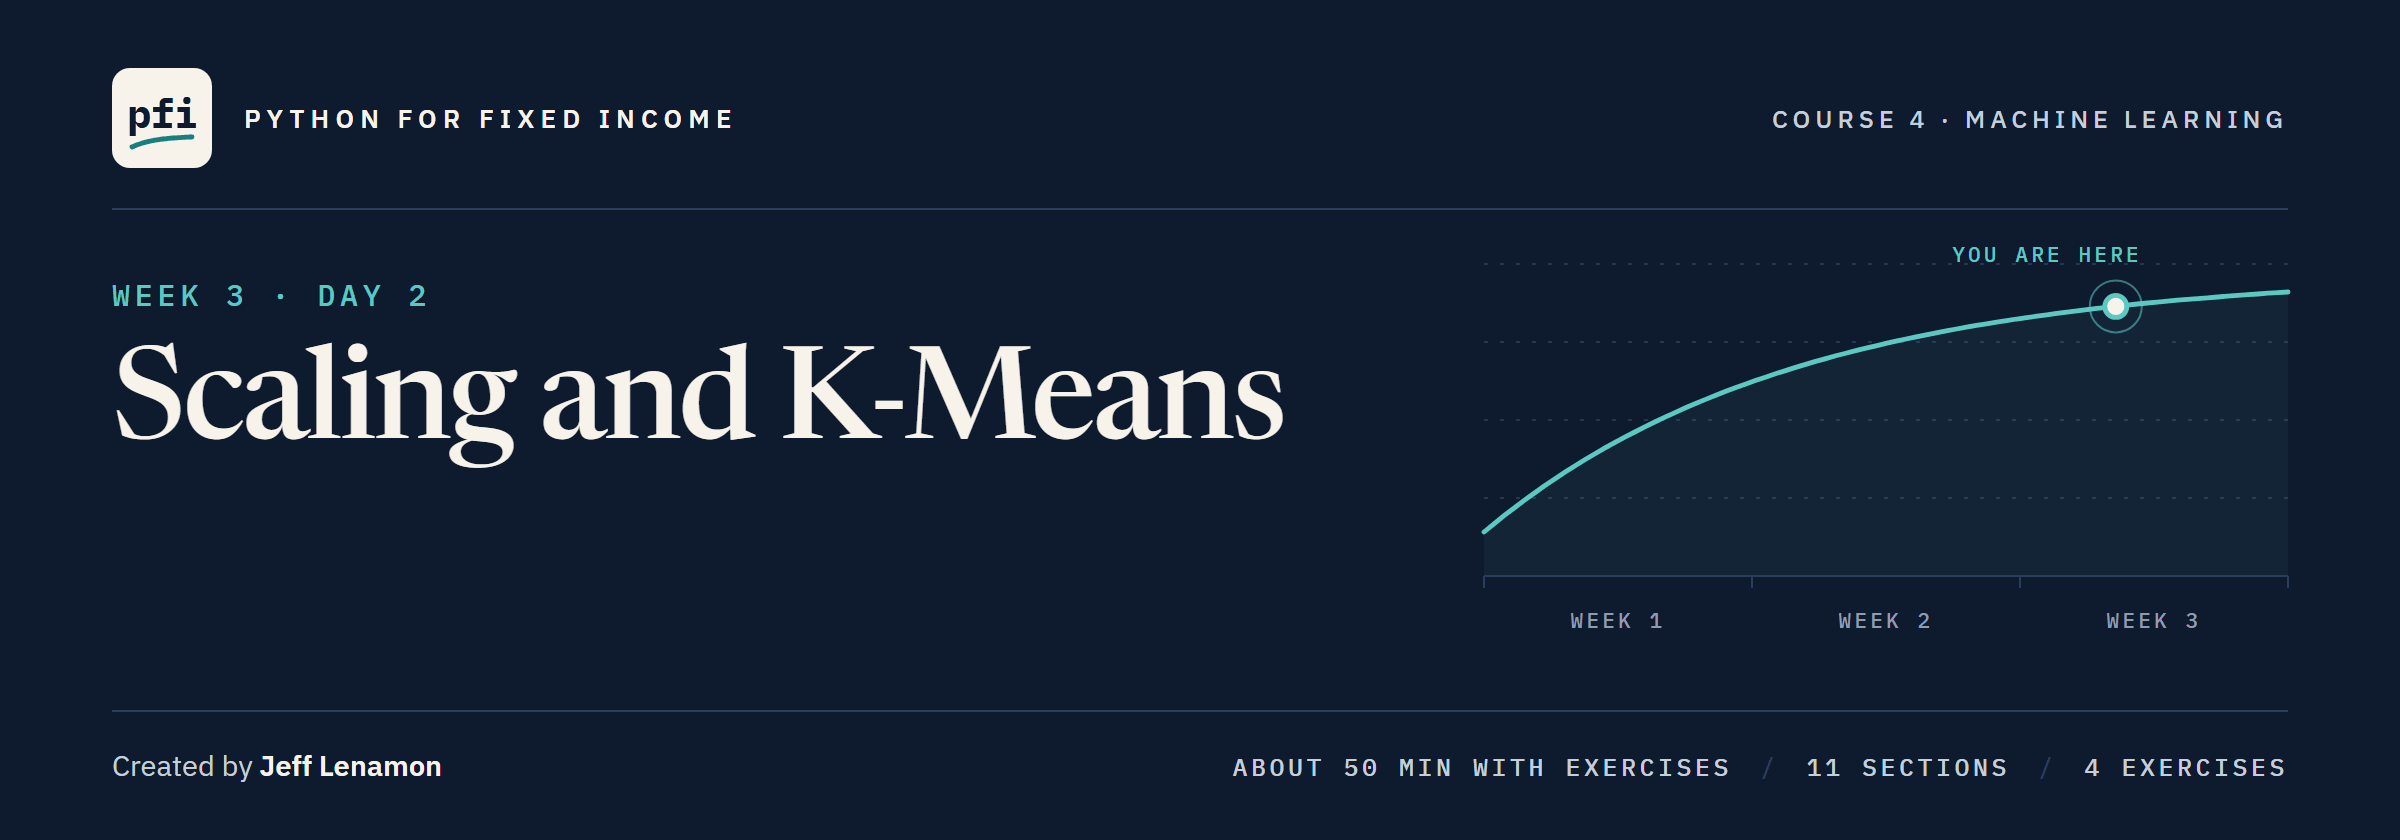

# Scaling and K-Means

Week 3, Day 2. Group 821 bonds by how alike they are with K-means, watch the units decide the groups, scale the columns, and choose the number of clusters as a judgement.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course04_machine_learning/week3/day2/12_scaling_and_k_means.ipynb)

# Problem Statement

## Business Context

A credit team wants a quick map of the 821-bond benchmark: which bonds look alike on spread, duration, coupon and rating.
No column in the file says what the groups should be, so there is no target today.
The model has to find the groups on its own: this is **unsupervised learning**.
The bonds and issuers are invented for this course.

## Objectives

Group the bonds with K-means, show that the columns' units can decide the groups and fix that by scaling, choose the number of clusters with the elbow and the silhouette, and describe each cluster in the file's own units.

## Data Dictionary

`benchmark.csv`, one row per bond:

1. `cusip`: the bond's identifier
2. `issuer`: the issuer's name
3. `rating`: credit rating, AAA to CCC
4. `oas`: option-adjusted spread, bp
5. `duration`: modified duration, years
6. `coupon`: annual coupon, % of par
7. `amount_outstanding`: face value outstanding, dollars (Exercise 1)

The file's other columns are not used today.

`ratings.csv` adds `score` (1 for AAA up to 18 for CCC, one step per notch) and `grade` (Investment Grade or High Yield).

## Your Route Through Day 2

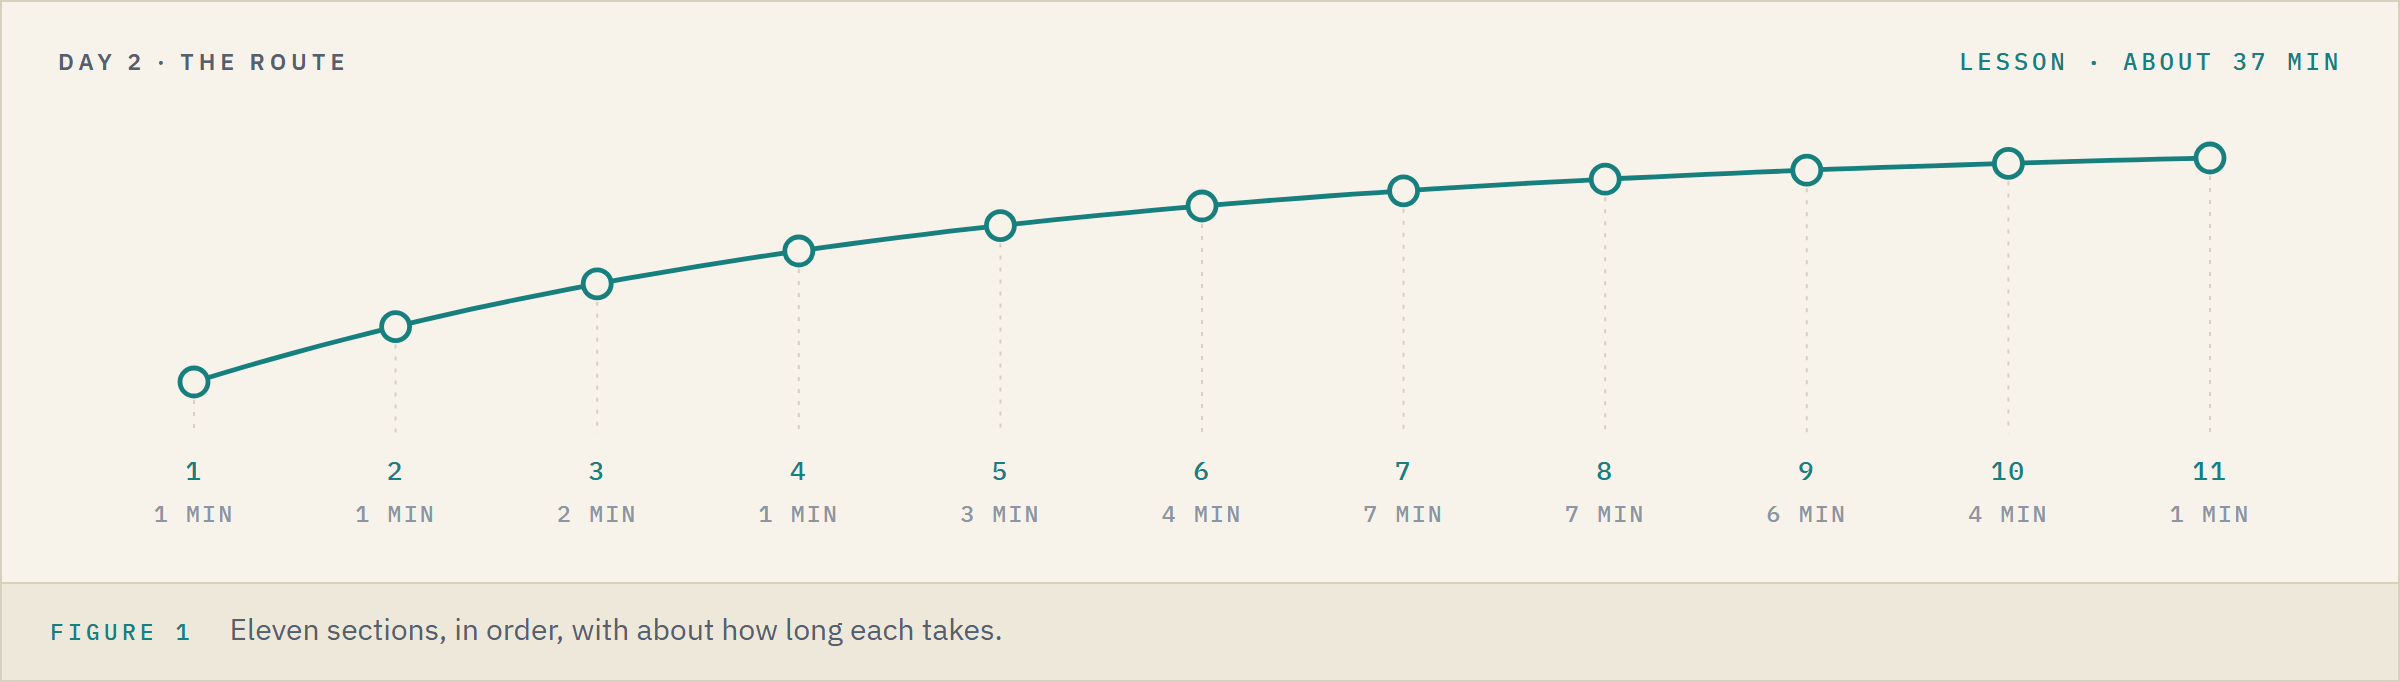

<table align="left">
<tr><th align="left"></th><th align="left">Section</th><th align="left">About</th></tr>
<tr><td align="left">1</td><td align="left">Setting Up</td><td align="left">1 min</td></tr>
<tr><td align="left">2</td><td align="left">Loading the Data</td><td align="left">1 min</td></tr>
<tr><td align="left">3</td><td align="left">Data Overview</td><td align="left">2 min</td></tr>
<tr><td align="left">4</td><td align="left">Exploratory Data Analysis</td><td align="left">1 min</td></tr>
<tr><td align="left">5</td><td align="left">Distance Between Two Bonds</td><td align="left">3 min</td></tr>
<tr><td align="left">6</td><td align="left">K-Means on the File's Units</td><td align="left">4 min</td></tr>
<tr><td align="left">7</td><td align="left">Scaling the Columns</td><td align="left">7 min</td></tr>
<tr><td align="left">8</td><td align="left">Inside the Loop</td><td align="left">7 min</td></tr>
<tr><td align="left">9</td><td align="left">Choosing the Number of Clusters</td><td align="left">6 min</td></tr>
<tr><td align="left">10</td><td align="left">Describing the Clusters</td><td align="left">4 min</td></tr>
<tr><td align="left">11</td><td align="left">Insights and Conclusion</td><td align="left">1 min</td></tr>
</table>
<br clear="left">

**Time.** About 37 minutes for the lesson, then about 12 for the four exercises.

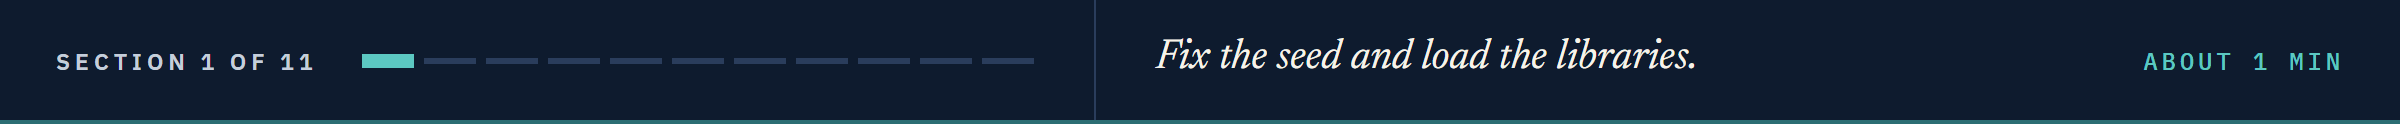

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts, still and interactive
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from ipywidgets import interact

# to measure distances, scale the columns, and group the bonds
from scipy.spatial.distance import pdist
from sklearn.metrics import pairwise_distances_argmin, silhouette_score, silhouette_samples
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# one look for every chart
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)

# one colour per cluster: the same colour-blind set, its pink moved ahead of a red that sits close to its orange
# color_palette() hands back the set's colours, and as_hex() writes each one as a text code plotly also reads
colours = sns.color_palette("colorblind").as_hex()
colours = [colours[i] for i in [0, 1, 2, 4, 3]]

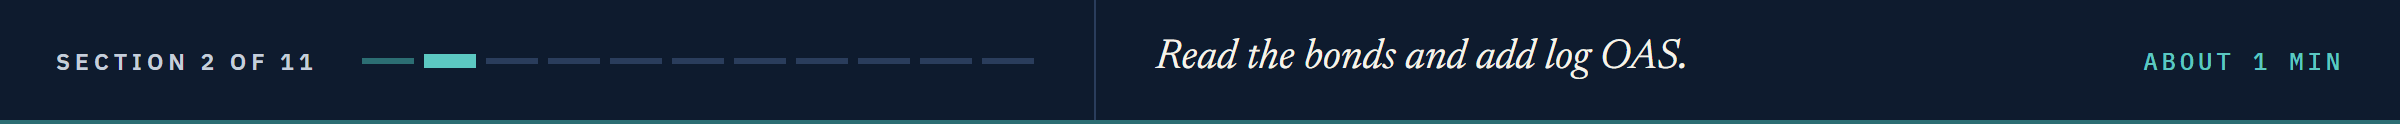

# Loading the Data

## Reading the Bonds and the Rating Scale

In [3]:
# the 821 bonds, with each rating's score and grade matched on
bonds = pd.read_csv(DATA + "benchmark.csv")
ratings = pd.read_csv(DATA + "ratings.csv")
data = bonds.merge(ratings[["rating", "score", "grade"]], on="rating")

# OAS on a log scale, as Day 4 used it: 50 to 100 bp is the same step as 500 to 1,000 bp
data["log_oas"] = np.log(data["oas"])

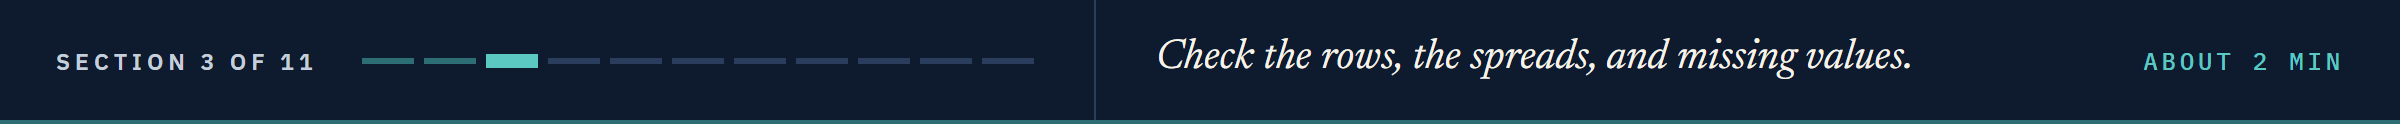

# Data Overview

## Checking the First Five Rows

Q. What does a bond look like on the columns we use today?

In [4]:
# the columns used today
data[["cusip", "issuer", "rating", "oas", "log_oas", "duration", "coupon", "score"]].head()

,cusip,issuer,rating,oas,log_oas,duration,coupon,score
0,99001BAA4,Quorvane Energy,BBB,83,4.418841,6.000,4.875,9
1,99001BAB2,Quorvane Energy,BBB,122,4.804021,6.834,5.750,9
2,99001BAC0,Quorvane Energy,BBB,123,4.812184,9.848,5.000,9
3,99001BAD8,Quorvane Energy,BBB,88,4.477337,0.933,3.875,9
4,99001BAE6,Quorvane Energy,BBB,127,4.844187,6.256,5.375,9


The first two bonds are both Quorvane Energy, both BBB.
We come back to them when we measure a distance.

## Checking the Statistical Summary

Q. How far does each column spread out?

In [5]:
# count, mean, standard deviation and range of each column
data[["oas", "log_oas", "duration", "coupon", "score"]].describe().round(2)

,oas,log_oas,duration,coupon,score
count,821.00,821.00,821.00,821.00,821.00
mean,179.08,4.89,5.98,5.85,9.25
std,185.52,0.74,3.25,1.66,3.43
min,15.00,2.71,0.92,1.50,1.00
25%,79.00,4.37,3.43,4.75,7.00
50%,125.00,4.83,5.92,5.62,9.00
75%,210.00,5.35,7.74,6.75,11.00
max,2074.00,7.64,16.04,11.00,18.00


One standard deviation of OAS is 185.52 bp.
One standard deviation of duration is 3.25 years, of coupon 1.66 percent, and of the rating score 3.43 notches.

## Checking for Missing and Duplicate Values

In [6]:
# missing values anywhere in the file, and CUSIPs that appear twice
print(data.isnull().sum().sum(), data["cusip"].duplicated().sum())

0 0


No missing values and no duplicate CUSIPs.

**The same clean 821 bonds as week 1, but their columns live on very different scales.**

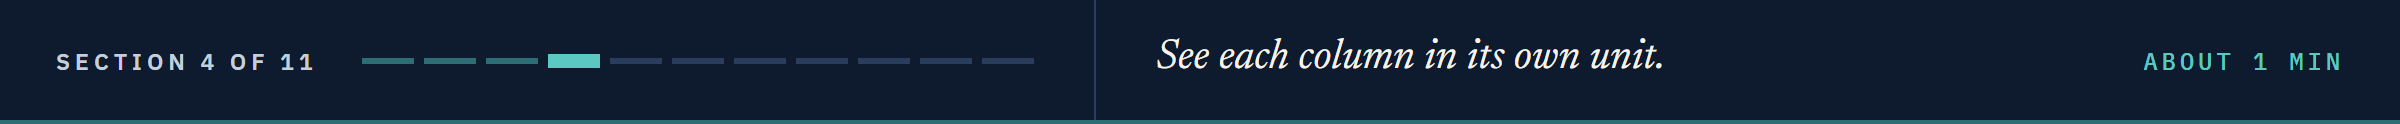

# Exploratory Data Analysis

## Univariate Analysis

### Four Columns, Four Units

Q. What does each column look like in its own unit?

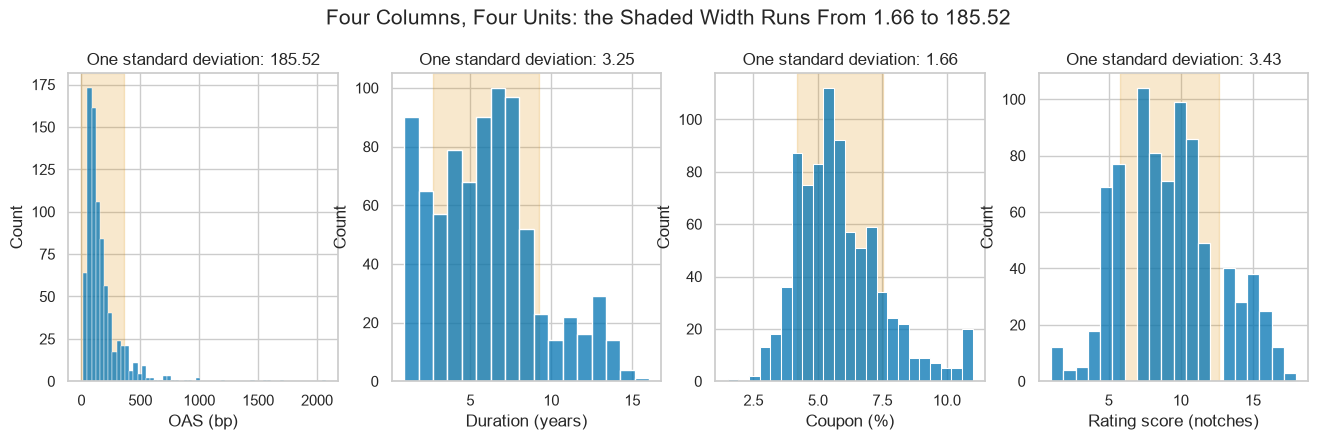

In [7]:
# one histogram per column in its own unit, the mean plus or minus one standard deviation shaded
units = {"oas": "OAS (bp)", "duration": "Duration (years)", "coupon": "Coupon (%)", "score": "Rating score (notches)"}
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (column, label) in zip(axes, units.items()):
    mean, sd = data[column].mean(), data[column].std()
    ax.axvspan(mean - sd, mean + sd, color=colours[1], alpha=0.2)
    sns.histplot(data=data, x=column, ax=ax)
    ax.set_xlabel(label)
    ax.set_title(f"One standard deviation: {sd:.2f}")
fig.suptitle("Four Columns, Four Units: the Shaded Width Runs From 1.66 to 185.52", fontsize=15, y=1.04)
plt.show()

OAS runs from 15 to 2,074 bp with a long tail to the right.
Duration runs from 0.9 to 16.0 years, coupon from 1.5 to 11.0 percent, the score from 1 to 18.
Each shaded strip is one standard deviation either side of the mean: the same idea, in four very different sizes.

**There is no target column today. The question is which bonds sit close together, so we need a distance.**

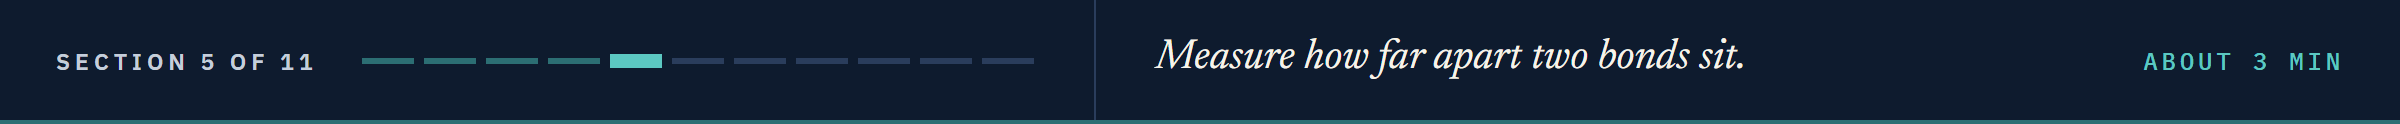

# Distance Between Two Bonds

## Measuring the Distance

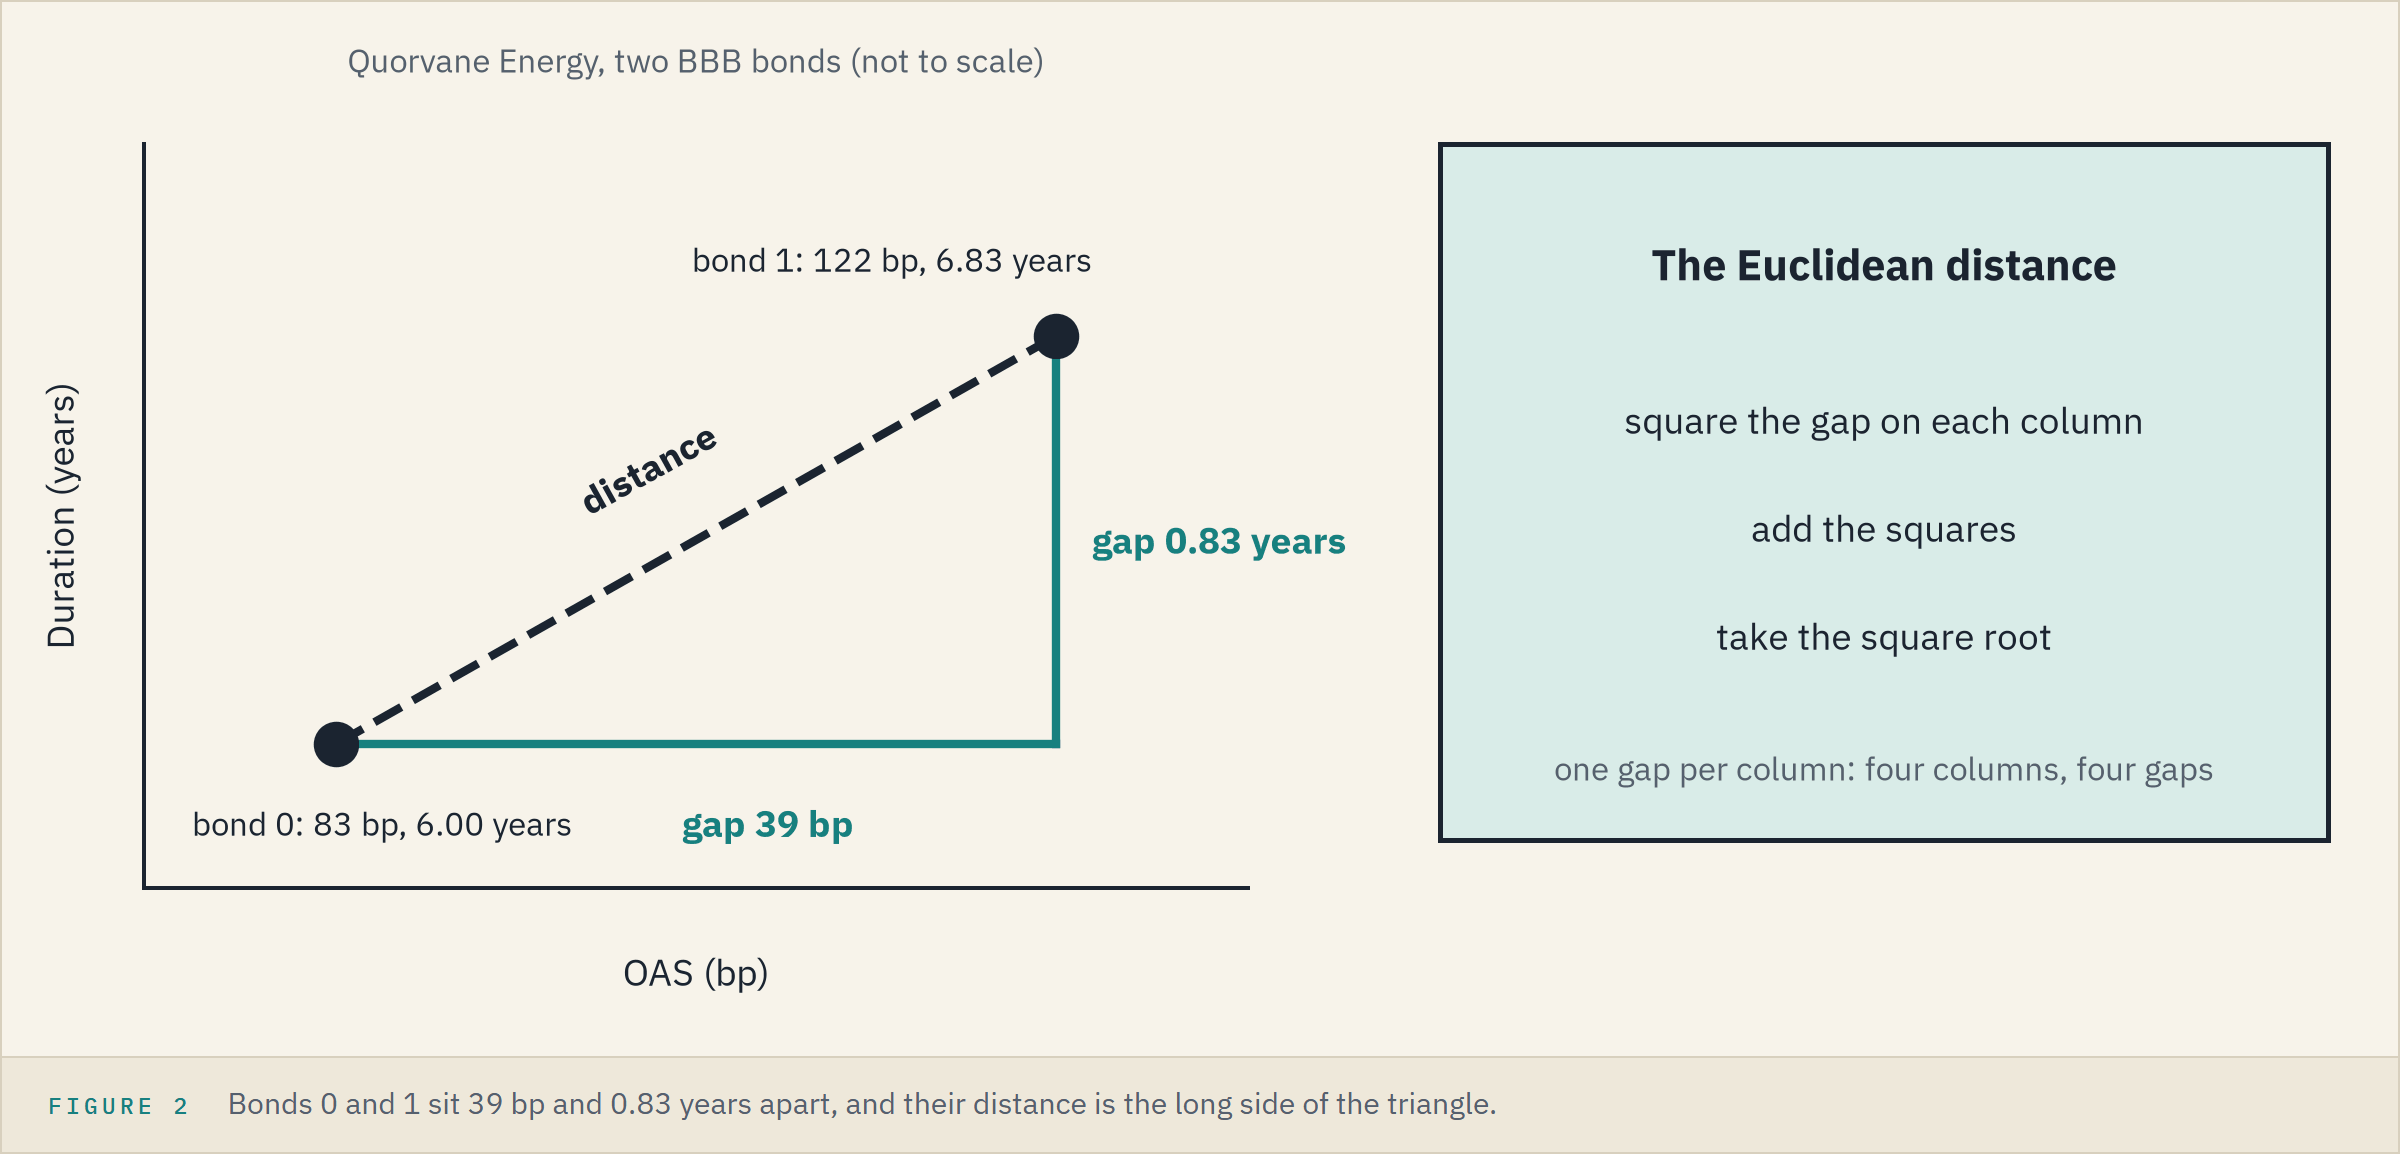

The distance between two bonds is the straight line between them, as in Pythagoras.
Square the gap on each column, add the squares, take the square root.
This is the **Euclidean distance**, and it works for any number of columns.

In [8]:
# the first two bonds on four columns, and the gap on each column
first_two = data.loc[[0, 1], ["oas", "duration", "coupon", "score"]]
gaps = first_two.iloc[1] - first_two.iloc[0]
print(gaps.round(3).to_dict())

# square the gaps, add them up, take the square root
print("Distance:", round(np.sqrt((gaps ** 2).sum()), 1))

{'oas': 39.0, 'duration': 0.834, 'coupon': 0.875, 'score': 0.0}
Distance: 39.0


## Which Column Makes Up the Distance

**Predict 1**

Q. What percent of the squared distance between these two bonds comes from OAS?

In [9]:
# each column's share of the squared distance, in percent
share = gaps ** 2 / (gaps ** 2).sum() * 100
share.round(2)

oas         99.90
duration     0.05
coupon       0.05
score        0.00
dtype: float64

99.9 percent of the squared distance is OAS.
The two bonds differ by 0.83 years of duration and 0.875 percent of coupon, and the distance barely notices.

## Every Pair of Bonds

Q. Is that pair unusual?
`pdist` gives a distance for every pair of rows in one call; `"sqeuclidean"` asks for the squared one.

In [10]:
# the squared gap on each column, for every pair of the 821 bonds
pair_gaps = pd.DataFrame({column: pdist(data[[column]], "sqeuclidean") for column in ["oas", "duration", "coupon", "score"]})
oas_share = pair_gaps["oas"] / pair_gaps.sum(axis=1) * 100
print(len(pair_gaps), "pairs")
print("Median OAS share:", round(oas_share.median(), 1), "percent")
print("Pairs where OAS is over 90 percent:", round((oas_share > 90).mean() * 100, 1), "percent")

336610 pairs
Median OAS share: 99.6 percent
Pairs where OAS is over 90 percent: 90.2 percent


Across all 336,610 pairs, OAS's median share of the squared distance is 99.6 percent.
For 90.2 percent of the pairs it is over 90 percent.

**In the file's units a distance is OAS with a little noise. K-means is built on distance, so we see what that does to it.**

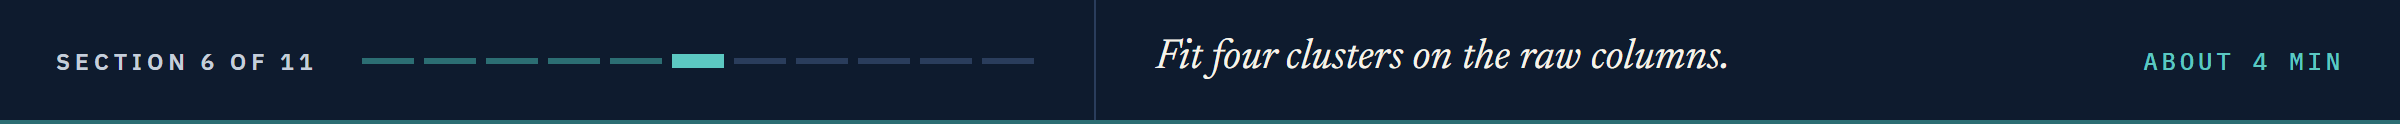

# K-Means on the File's Units

## How K-Means Works

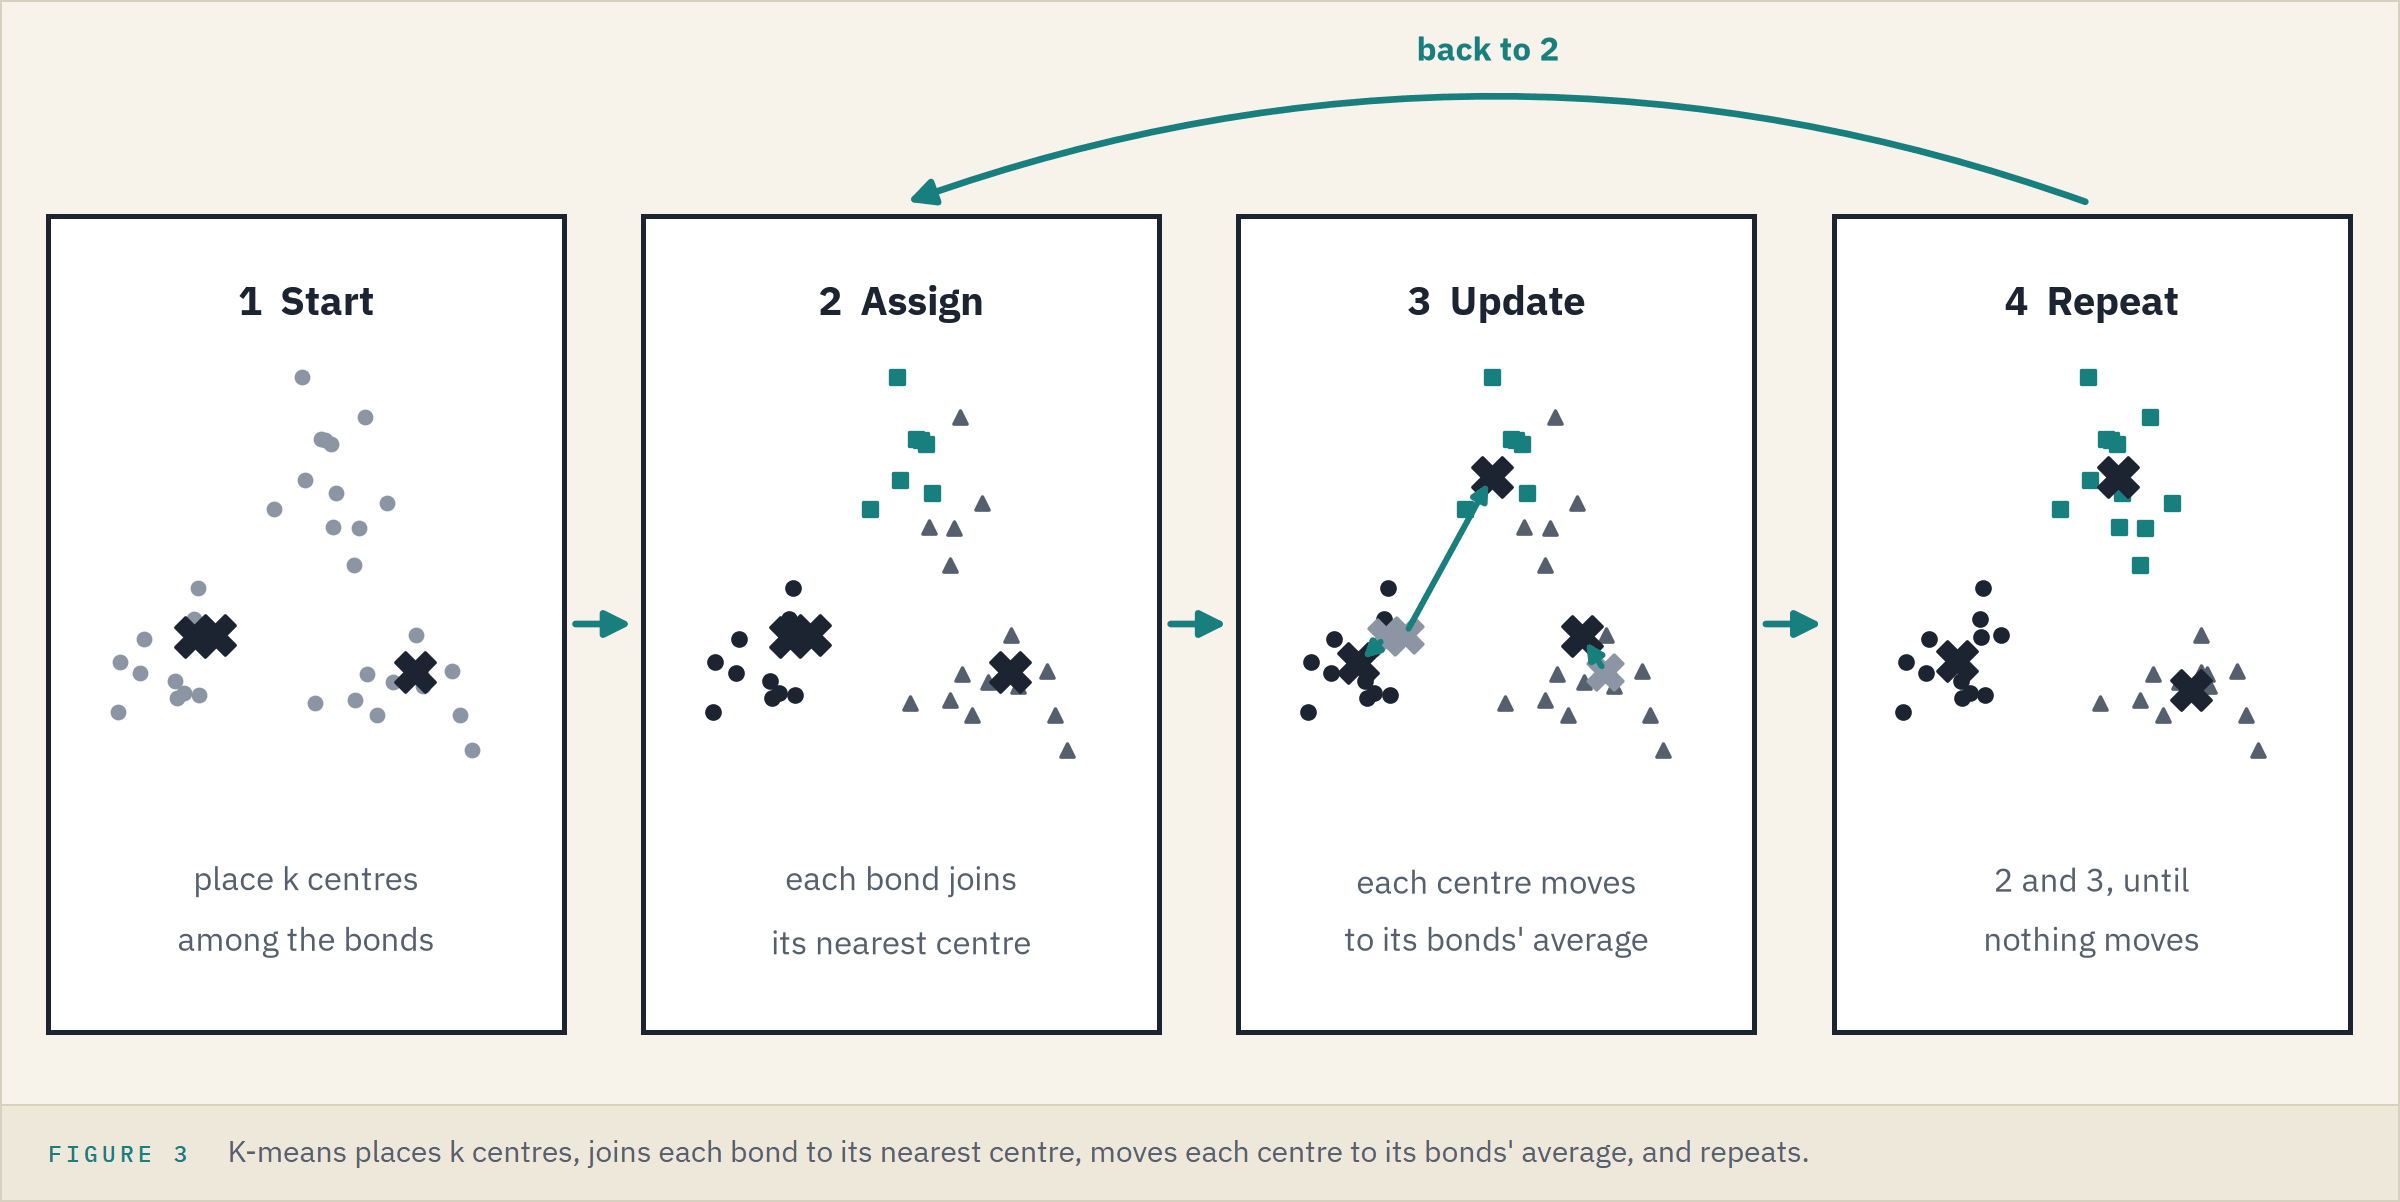

K-means splits the rows into k groups, called **clusters**, with a loop:

* **Start**: place k centres among the rows.
* **Assign**: each bond joins its nearest centre.
* **Update**: each centre moves to the average of its bonds.
* **Repeat** until no bond changes centre: the loop has **converged**.

**Inertia** adds up the squared distance from every bond to its own centre: the lower, the tighter the clusters.
scikit-learn places the starting centres with **k-means++**, which spreads them out.
A loop can still settle in a poor place, so `n_init=10` runs it from ten starts and keeps the lowest inertia.

## Fitting Four Clusters

In [11]:
# the four columns in the file's own units: OAS in bp
X_raw = data[["oas", "duration", "coupon", "score"]]

# four clusters, ten starts, the course seed
kmeans_raw = KMeans(n_clusters=4, n_init=10, random_state=SEED)
kmeans_raw.fit(X_raw)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",4
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](4, 4)","[[ 97

`labels_` holds each bond's cluster, numbered 0 to 3 in no particular order.
We number them by size, largest first, so every chart and table reads the same way.

In [12]:
# number the clusters by size: the largest becomes cluster 0
def by_size(labels):
    sizes = pd.Series(labels).value_counts()
    new_number = {old: new for new, old in enumerate(sizes.index)}
    return pd.Series(labels).map(new_number)

data["raw_cluster"] = by_size(kmeans_raw.labels_)
data["raw_cluster"].value_counts()

raw_cluster
0    558
1    212
2     45
3      6
Name: count, dtype: int64

## Where the Clusters Sit

**Predict 2**

Q. Sketch duration up the side against OAS along the bottom. Where do the four clusters sit?

In [13]:
# each cluster's lowest and highest OAS in bp, and its shortest and longest duration in years
spans = data.groupby("raw_cluster").agg(oas_low=("oas", "min"), oas_high=("oas", "max"),
                                        duration_low=("duration", "min"), duration_high=("duration", "max"))
spans

,oas_low,oas_high,duration_low,duration_high
raw_cluster,,,,
0,15,181,0.933,16.042
1,182,418,0.915,12.707
2,427,1004,1.201,9.536
3,1215,2074,1.546,5.207


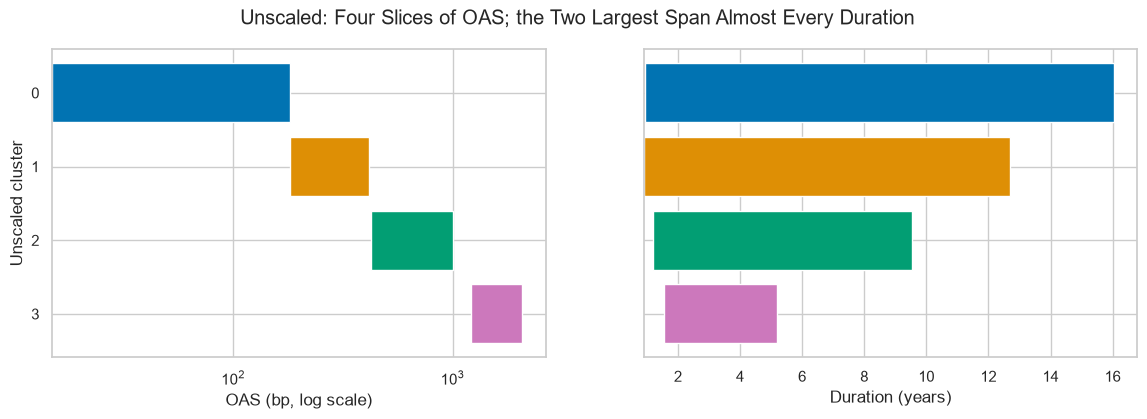

In [14]:
# one bar per cluster from its lowest value to its highest; left= sets where each bar starts
fig, (left, right) = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
left.barh(spans.index, spans["oas_high"] - spans["oas_low"], left=spans["oas_low"], color=colours[:4])
right.barh(spans.index, spans["duration_high"] - spans["duration_low"], left=spans["duration_low"], color=colours[:4])
left.set_xscale("log")
left.set_xlabel("OAS (bp, log scale)")
right.set_xlabel("Duration (years)")
left.set_ylabel("Unscaled cluster")
left.set_yticks(range(4))
left.invert_yaxis()
fig.suptitle("Unscaled: Four Slices of OAS; the Two Largest Span Almost Every Duration")
plt.show()

The clusters are four slices of OAS: 15 to 181, 182 to 418, 427 to 1,004 and 1,215 to 2,074 bp.
The slices meet end to end and never overlap.
The two largest clusters each run from under 1 year to more than 12 years of duration: duration played no part.
The six widest bonds are a cluster of their own.

**Four slices of OAS, chosen by its units, not by the bonds. We scale the columns.**

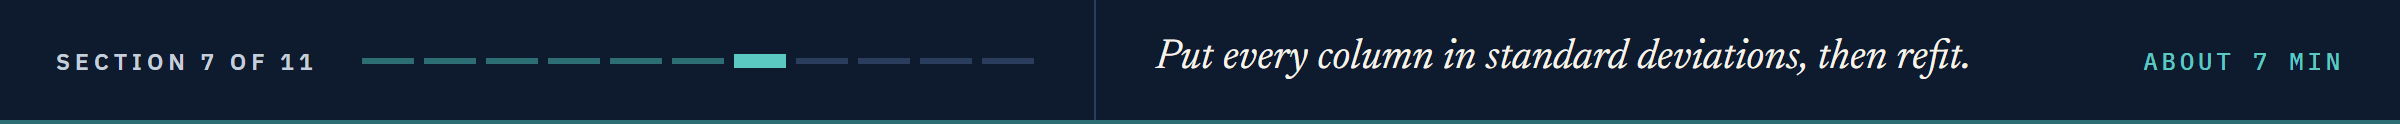

# Scaling the Columns

## StandardScaler

`StandardScaler` (Day 5's scaling step) turns each column into its z-score, as in Course 1: minus the column's mean, divided by its standard deviation.
Every column then has mean 0 and standard deviation 1, so a gap of 1 is one standard deviation on any column.
From here K-means gets log OAS in place of OAS, so the long tail of wide bonds does not stretch every distance.

In [15]:
# the four columns K-means gets from here on
features = ["log_oas", "duration", "coupon", "score"]

# fit the scaler on all 821 bonds and scale them
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(data[features]), columns=features)
X_scaled.describe().round(2)

,log_oas,duration,coupon,score
count,821.00,821.00,821.00,821.00
mean,-0.00,-0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00
min,-2.97,-1.56,-2.63,-2.40
25%,-0.71,-0.78,-0.67,-0.66
50%,-0.08,-0.02,-0.14,-0.07
75%,0.62,0.54,0.54,0.51
max,3.74,3.09,3.11,2.55


Every column now has mean 0 and standard deviation 1.00.
The scaler is fitted on all 821 bonds: clustering keeps no rows back, because there is no score on unseen rows to protect.

## Before and After

Q. How far apart were the columns' spreads, and where are they now?

In [16]:
# each column's standard deviation in its own unit, then after scaling (OAS last, so it is drawn at the top)
columns = ["score", "coupon", "duration", "log_oas", "oas"]
spread = pd.DataFrame({"before": data[columns].std(),
                       "after": StandardScaler().fit_transform(data[columns]).std(axis=0)})
spread.round(2)

,before,after
score,3.43,1.0
coupon,1.66,1.0
duration,3.25,1.0
log_oas,0.74,1.0
oas,185.52,1.0


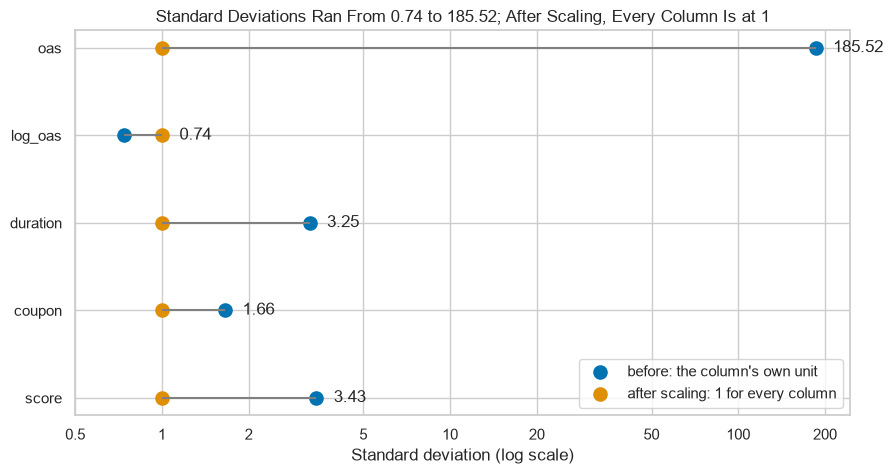

In [17]:
# a dumbbell, as Day 2 drew: one line per column from after to before, on a log axis
plt.hlines(spread.index, spread["after"], spread["before"], color="gray")
plt.scatter(spread["before"], spread.index, s=90, label="before: the column's own unit")
plt.scatter(spread["after"], spread.index, s=90, label="after scaling: 1 for every column")
# each column's own standard deviation beside its dot; va= centres the text on the row
for name, value in spread["before"].items():
    plt.text(max(value, 1) * 1.15, name, f"{value:.2f}", va="center")
plt.xscale("log")
plt.xticks([0.5, 1, 2, 5, 10, 20, 50, 100, 200], ["0.5", "1", "2", "5", "10", "20", "50", "100", "200"])
plt.xlabel("Standard deviation (log scale)")
plt.legend(loc="lower right")
plt.title("Standard Deviations Ran From 0.74 to 185.52; After Scaling, Every Column Is at 1")
plt.show()

Before scaling, OAS's standard deviation was about 57 times duration's.
After, every column sits at 1.

## The Same Pair, Scaled

Q. How much of the first two bonds' distance comes from each column now?

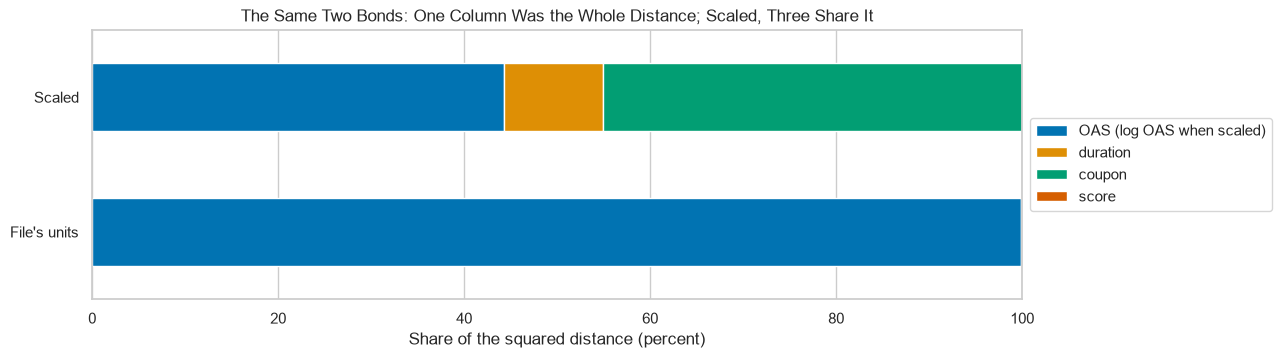

log_oas     44.3
duration    10.6
coupon      45.1
score        0.0
dtype: float64

In [18]:
# the first two bonds' gaps, scaled, as shares of their squared distance
scaled_gaps = X_scaled.iloc[1] - X_scaled.iloc[0]
scaled_share = scaled_gaps ** 2 / (scaled_gaps ** 2).sum() * 100

# both shares as 100 percent bars, one segment per column
shares = pd.DataFrame({"File's units": share.to_numpy(), "Scaled": scaled_share.to_numpy()},
                      index=["OAS (log OAS when scaled)", "duration", "coupon", "score"]).T
shares.plot.barh(stacked=True, figsize=(12, 3.5))
plt.xlabel("Share of the squared distance (percent)")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))  # the legend outside, to the right
plt.title("The Same Two Bonds: One Column Was the Whole Distance; Scaled, Three Share It")
plt.show()
scaled_share.round(1)

Scaled, log OAS is 44.3 percent of the pair's squared distance, coupon 45.1 and duration 10.6.
The score is 0 because both bonds are BBB.

## Fitting Four Clusters Again

In [19]:
# the same model on the scaled columns
kmeans = KMeans(n_clusters=4, n_init=10, random_state=SEED)
kmeans.fit(X_scaled)
data["cluster"] = by_size(kmeans.labels_)
print("Inertia:", round(kmeans.inertia_, 1))
data["cluster"].value_counts()

Inertia: 1141.8


cluster
0    278
1    239
2    175
3    129
Name: count, dtype: int64

Four clusters of 278, 239, 175 and 129 bonds: no cluster is a handful of outliers now.

## Same Bonds, Three Answers

Q. What if OAS were written in percent, 83 bp as 0.83, with no scaling?

In [20]:
# the unscaled columns again, with OAS in percent
X_pct = X_raw.assign(oas=X_raw["oas"] / 100)
kmeans_pct = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X_pct)
data["pct_cluster"] = by_size(kmeans_pct.labels_)

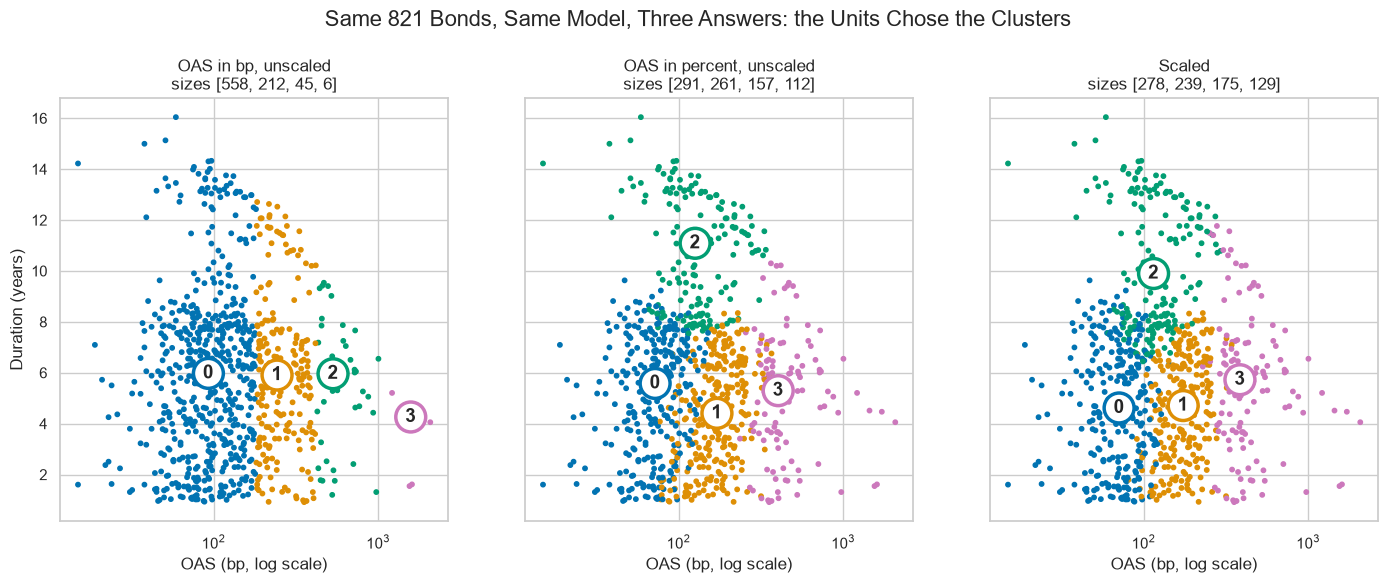

In [21]:
# the same 821 bonds three times, coloured by each answer's clusters, each cluster's number at its median bond
answers = {"OAS in bp, unscaled": "raw_cluster", "OAS in percent, unscaled": "pct_cluster", "Scaled": "cluster"}
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5), sharey=True)
for ax, (name, column) in zip(axes, answers.items()):
    ax.scatter(data["oas"], data["duration"], c=[colours[c] for c in data[column]], s=10)
    middles = data.groupby(column)[["oas", "duration"]].median()
    # bbox draws a ring in the cluster's colour behind each number
    for number in middles.index:
        ax.text(middles.loc[number, "oas"], middles.loc[number, "duration"], number, fontsize=14, weight="bold",
                ha="center", va="center", bbox={"boxstyle": "circle", "facecolor": "white", "edgecolor": colours[number], "linewidth": 2.5})
    ax.set_xscale("log")
    ax.set_title(f"{name}\nsizes {data[column].value_counts().tolist()}")
    ax.set_xlabel("OAS (bp, log scale)")
axes[0].set_ylabel("Duration (years)")
fig.suptitle("Same 821 Bonds, Same Model, Three Answers: the Units Chose the Clusters", fontsize=16, y=1.04)
plt.show()

In bp, OAS is the loudest column and the clusters are vertical stripes of spread.
In percent, OAS shrinks to 0.15 to 20.74, and duration and the rating score become the loudest columns.
Cluster 2 is 157 bonds of 7.5 to 16.0 years, and the other three split mostly by rating score.
Scaled, the clusters cut across both axes, because spread, duration, coupon and rating all have a say.

## Changing the Units After Scaling

Q. Once the columns are scaled, do the units still matter?

In [22]:
# OAS in percent and duration in months, then scaled and clustered as before
other_units = data[features].assign(log_oas=np.log(data["oas"] / 100), duration=data["duration"] * 12)
other_scaled = StandardScaler().fit_transform(other_units)
other = by_size(KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(other_scaled).labels_)
print("Bonds that change cluster:", (other != data["cluster"]).sum(), "of 821")

Bonds that change cluster: 0 of 821


Percent shifts every log OAS by the same amount and months multiply every duration by 12, and neither changes a z-score.
Not one bond moves: scaled, the units no longer choose.

## Where the Unscaled Clusters Went

Q. Where did each unscaled cluster's bonds land once the columns were scaled?

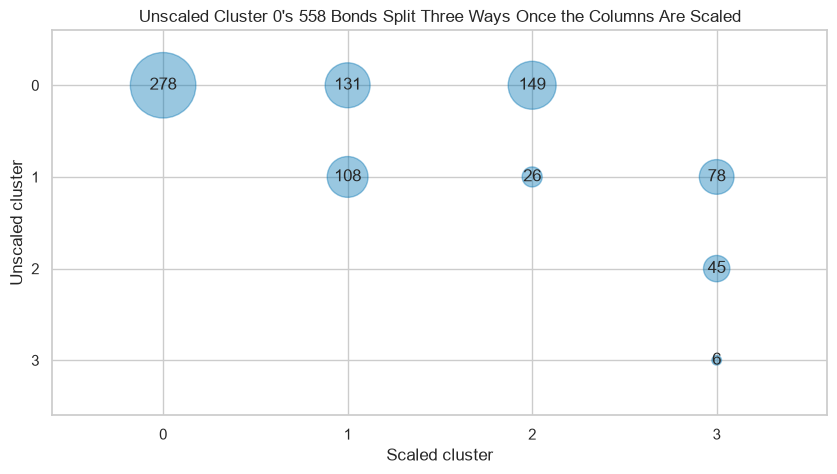

In [23]:
# count the bonds in each pair of clusters; stack() turns the table into one row per pair
moves = pd.crosstab(data["raw_cluster"], data["cluster"]).stack().reset_index(name="bonds")
moves = moves[moves["bonds"] > 0]

# one circle per pair: its area is the count
plt.scatter(moves["cluster"], moves["raw_cluster"], s=moves["bonds"] * 8, color=colours[0], alpha=0.4)
for x, y, bonds in zip(moves["cluster"], moves["raw_cluster"], moves["bonds"]):
    plt.text(x, y, bonds, ha="center", va="center", fontsize=12)
plt.xticks(range(4))
plt.yticks(range(4))
plt.axis([-0.6, 3.6, 3.6, -0.6])  # x from -0.6 to 3.6, y from 3.6 down to -0.6: cluster 0 at the top
plt.xlabel("Scaled cluster")
plt.ylabel("Unscaled cluster")
plt.title("Unscaled Cluster 0's 558 Bonds Split Three Ways Once the Columns Are Scaled")
plt.show()

Unscaled cluster 0's 558 bonds split 278, 131 and 149 across three scaled clusters.
The 51 widest bonds, unscaled clusters 2 and 3, all land in scaled cluster 3.

**Scaled, every column has a say. Now we open the loop and watch it work.**

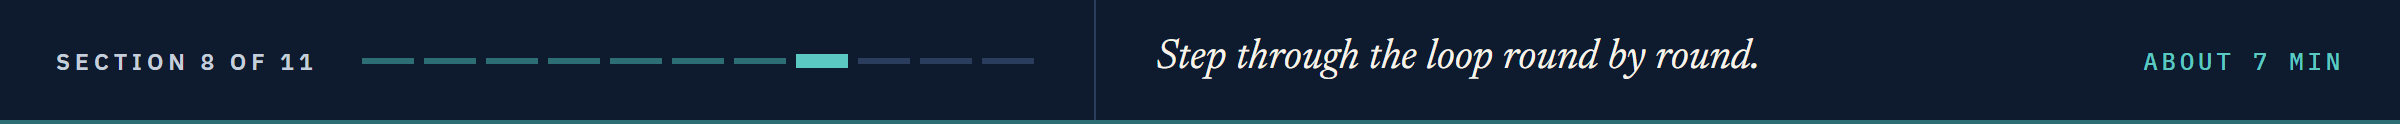

# Inside the Loop

## The Loop by Hand

Q. What does the loop do, round by round?
Two scaled columns are enough to draw it: log OAS and duration.
`pairwise_distances_argmin(rows, centres)` gives each row the number of its nearest centre: the assign step in one call.

In [24]:
# two scaled columns, so the loop can be drawn on a page
two = X_scaled[["log_oas", "duration"]]

# start from the first four bonds in the file, all Quorvane Energy BBB: a poor start on purpose
centres = [two.iloc[:4].to_numpy()]

# fourteen rounds: assign each bond to its nearest centre, then move each centre to its bonds' average
for round_number in range(14):
    nearest = pairwise_distances_argmin(two, centres[-1])
    centres.append(two.groupby(nearest).mean().to_numpy())

In [25]:
# inertia at the start and after each round: each bond's squared distance to its nearest centre, added up
inertia = []
for round_centres in centres:
    nearest = pairwise_distances_argmin(two, round_centres)
    inertia.append(((two.to_numpy() - round_centres[nearest]) ** 2).sum())
print([round(float(value), 1) for value in inertia])

[962.5, 577.1, 543.1, 535.5, 532.5, 529.2, 526.7, 524.8, 522.9, 521.7, 521.3, 520.9, 520.7, 520.6, 520.6]


In [26]:
# scikit-learn from the same start: init= hands it the starting centres, n_init=1 runs the loop once
same_start = KMeans(n_clusters=4, init=centres[0], n_init=1, random_state=SEED).fit(two)
print("Rounds:", same_start.n_iter_, " Same centres:", np.allclose(same_start.cluster_centers_, centres[-1]))

Rounds: 14  Same centres: True


Inertia falls from 962.5 to 577.1 in the first round, then creeps down to 520.6.
scikit-learn took the same 14 rounds to the same centres: K-means is those two lines, repeated.

## Step Through the Rounds

Move the slider through the rounds.
Each coloured tile is the patch of the page nearest one centre.
`contourf` fills a grid of points with the colour of their nearest centre, as Day 6 filled its hill.

In [27]:
# a fine grid of points over the page, one row per point
grid_x, grid_y = np.meshgrid(np.linspace(-3.2, 3.9, 300), np.linspace(-1.8, 3.3, 300))
grid = pd.DataFrame({"log_oas": grid_x.flatten(), "duration": grid_y.flatten()})

# one round on one set of axes: the tiles, the bonds, the centres
def draw_round(ax, round_number):
    tiles = pairwise_distances_argmin(grid, centres[round_number]).reshape(grid_x.shape)
    # levels= puts an edge between the centre numbers 0, 1, 2 and 3, so each number gets its own colour
    ax.contourf(grid_x, grid_y, tiles, levels=[-0.5, 0.5, 1.5, 2.5, 3.5], colors=colours[:4], alpha=0.35)
    ax.scatter(two["log_oas"], two["duration"], s=5, color="gray")
    ax.scatter(centres[round_number][:, 0], centres[round_number][:, 1], marker="X", s=220, color="black")
    ax.set_title(f"Round {round_number}: inertia {inertia[round_number]:.1f}")
    ax.set_xlabel("Log OAS (standard deviations)")
    ax.set_ylabel("Duration (standard deviations)")

In [28]:
# your turn: move the slider through the rounds
def step(round_number=0):
    fig, ax = plt.subplots(figsize=(9, 6))
    draw_round(ax, round_number)
    plt.show()

interact(step, round_number=(0, 14, 1));

interactive(children=(IntSlider(value=0, description='round_number', max=14), Output()), _dom_classes=('widget…

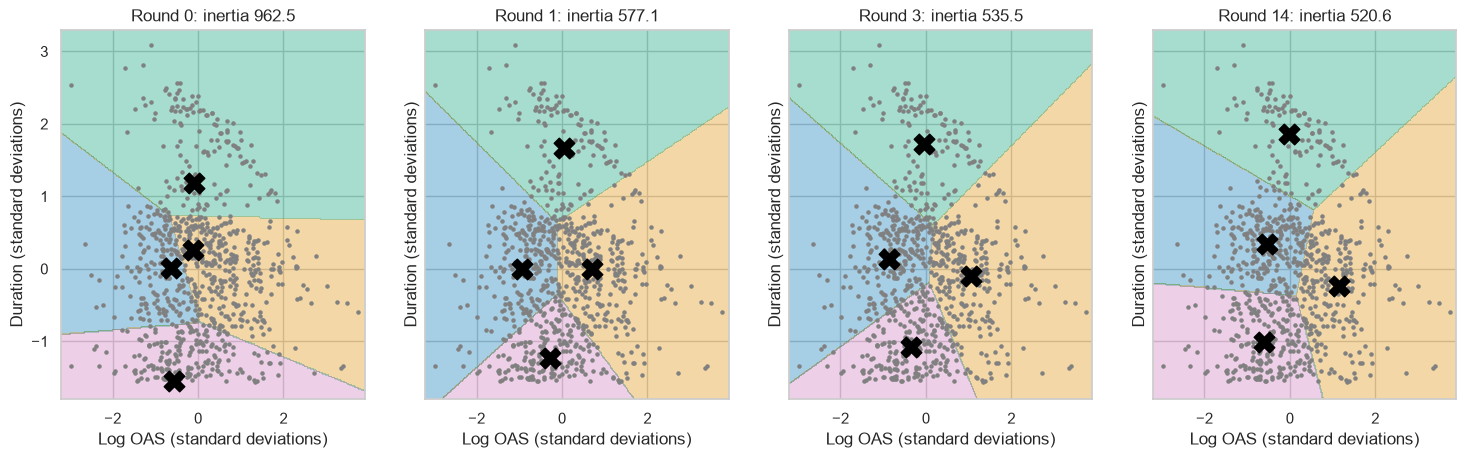

In [29]:
# rounds 0, 1, 3 and 14 side by side, drawn as a still picture (sliders do not run on GitHub)
fig, axes = plt.subplots(1, 4, figsize=(18, 4.8), sharey=True)
for ax, round_number in zip(axes, [0, 1, 3, 14]):
    draw_round(ax, round_number)
plt.show()

At round 0 the four centres are the first four bonds, in a narrow strip of log OAS.
One round of assign and update moves each of them out toward a crowd of bonds.
By round 3 inertia is 535.5, within 15 of its final 520.6, and the last eleven rounds only nudge the map.

## The Paths of the Centres

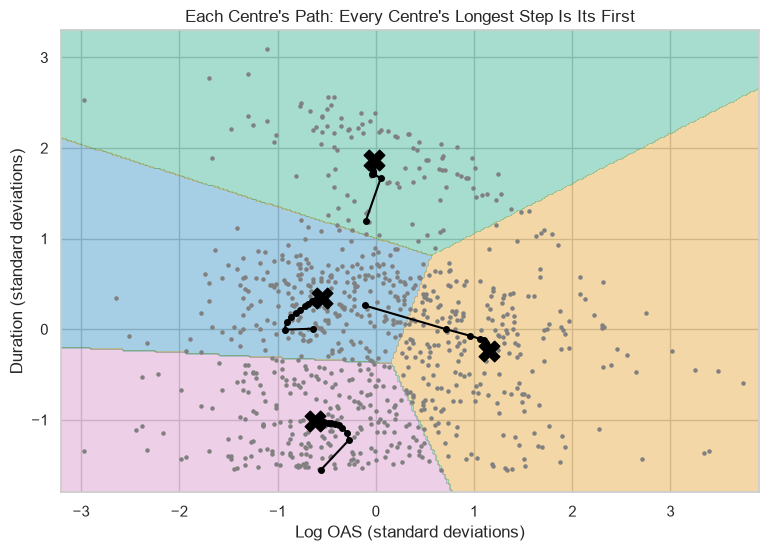

In [30]:
# every round's centres stacked into one array: rounds, then centres, then the two columns
paths = np.array(centres)

# each centre's path from its start (the first dot) to round 14, on the final tiles
fig, ax = plt.subplots(figsize=(9, 6))
draw_round(ax, 14)
for k in range(4):
    ax.plot(paths[:, k, 0], paths[:, k, 1], color="black", marker="o", markersize=4)
ax.set_title("Each Centre's Path: Every Centre's Longest Step Is Its First")
plt.show()

Every centre takes its longest step in the first round, then drifts in shorter and shorter steps.
Inertia never rises from one round to the next: neither joining the nearest centre nor moving a centre to its bonds' average can lengthen the total.

## One Start Against Ten

`init=` can start K-means anywhere, and `rng.choice(821, size=4, replace=False)` picks four different bonds at random.
We try 30 single starts on the four scaled columns, at k = 4 and at k = 8.

**Predict 3**

Q. The ten-start fit at k = 4 has inertia 1,141.8. How many of 30 single starts finish within 1 of it?

In [31]:
# 30 single starts from bonds picked at random, at k = 4 and at k = 8, beside the ten-start fit
rng = np.random.default_rng(SEED)
runs = []
for k in [4, 8]:
    best = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_scaled).inertia_
    for run in range(30):
        start = X_scaled.to_numpy()[rng.choice(821, size=k, replace=False)]
        single = KMeans(n_clusters=k, init=start, n_init=1, random_state=SEED).fit(X_scaled)
        runs.append({"k": k, "inertia": single.inertia_, "best": best})
runs = pd.DataFrame(runs)
runs["within_1"] = runs["inertia"] - runs["best"] < 1
runs.groupby("k")["within_1"].sum()

k
4    24
8     6
Name: within_1, dtype: int64

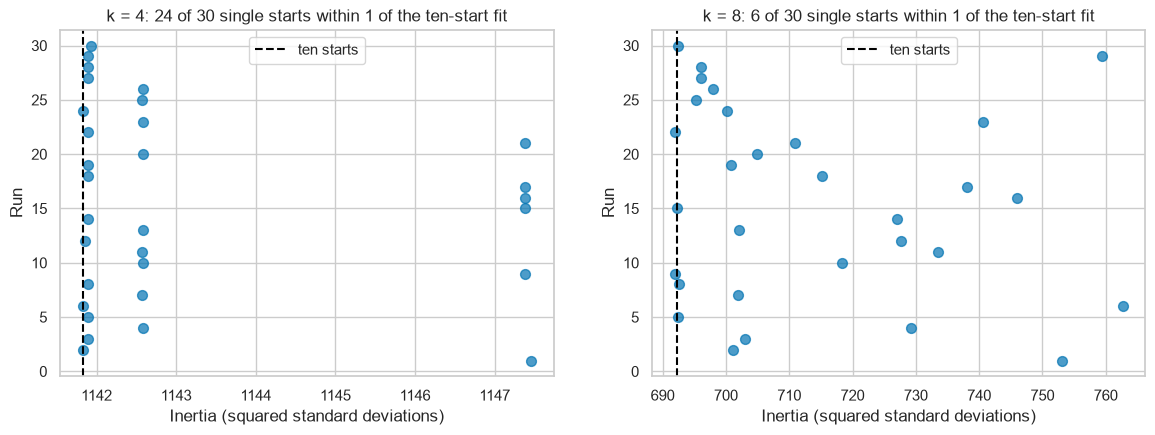

In [32]:
# each single start's inertia as a dot, one row per run, the ten-start fit dashed
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, k in zip(axes, [4, 8]):
    these = runs[runs["k"] == k]
    close = these["within_1"].sum()
    ax.scatter(these["inertia"], range(1, 31), s=50, alpha=0.7)
    ax.axvline(these["best"].iloc[0], color="black", linestyle="--", label="ten starts")
    ax.set_ylabel("Run")
    ax.set_title(f"k = {k}: {close} of 30 single starts within 1 of the ten-start fit")
    ax.set_xlabel("Inertia (squared standard deviations)")
    ax.legend(loc="upper center")
plt.show()

At k = 4, 24 of 30 single starts finish within 1 of 1,141.8, and the worst ends at 1,147.5.
At k = 8 only 6 of 30 do, and the worst ends at 762.7 against 692.3: more clusters, more poor places to settle.

**One start can settle badly, so `n_init=10` is always written out. The loop gives clusters for any k, so next we choose k.**

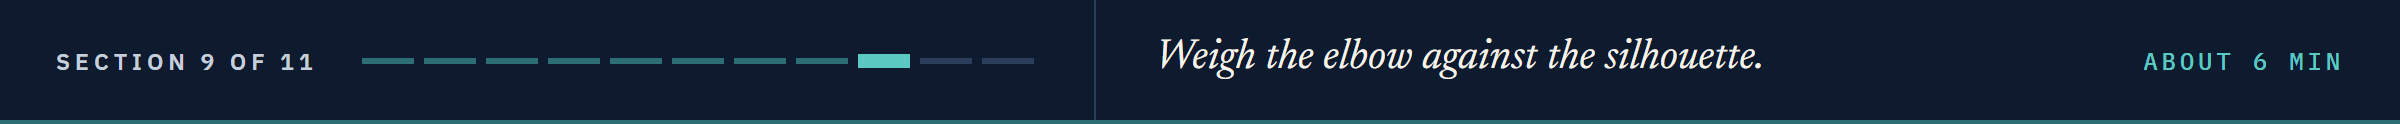

# Choosing the Number of Clusters

## The Elbow

Every extra cluster lowers inertia: with 821 clusters it would be 0.
The **elbow** is the k after which each extra cluster buys little.

In [33]:
# inertia for each number of clusters
def elbow_table(X, k_values):
    rows = []
    for k in k_values:
        model = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
        rows.append({"k": k, "inertia": model.inertia_})
    return pd.DataFrame(rows).set_index("k")

elbow = elbow_table(X_scaled, range(1, 11))
elbow["fall"] = -elbow["inertia"].diff()
elbow.round(1)

,inertia,fall
k,,
1,3284.0,NaN
2,1897.6,1386.4
3,1470.4,427.2
4,1141.8,328.5
5,987.5,154.3
6,868.1,119.4
7,763.9,104.2
8,692.3,71.6
9,633.6,58.8


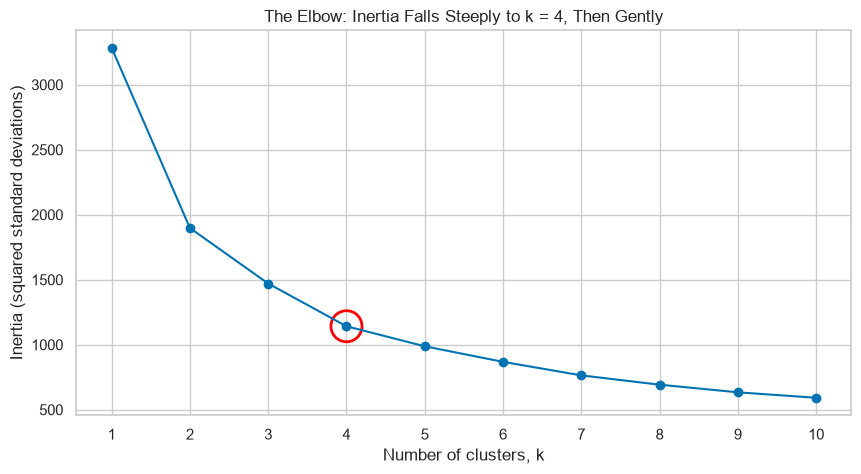

In [34]:
# inertia against k, the bend ringed
plt.plot(elbow.index, elbow["inertia"], marker="o")
plt.scatter(4, elbow.loc[4, "inertia"], s=500, facecolors="none", edgecolors="red", linewidths=2)
plt.xticks(elbow.index)
plt.xlabel("Number of clusters, k")
plt.ylabel("Inertia (squared standard deviations)")
plt.title("The Elbow: Inertia Falls Steeply to k = 4, Then Gently")
plt.show()

Inertia falls by 1,386.4, 427.2 and 328.5 over the first three steps, then by 154.3 from 4 to 5 and less after that.
The curve bends gradually, so the elbow is a reading: we read it at 4, after the last big fall.

## The Silhouette

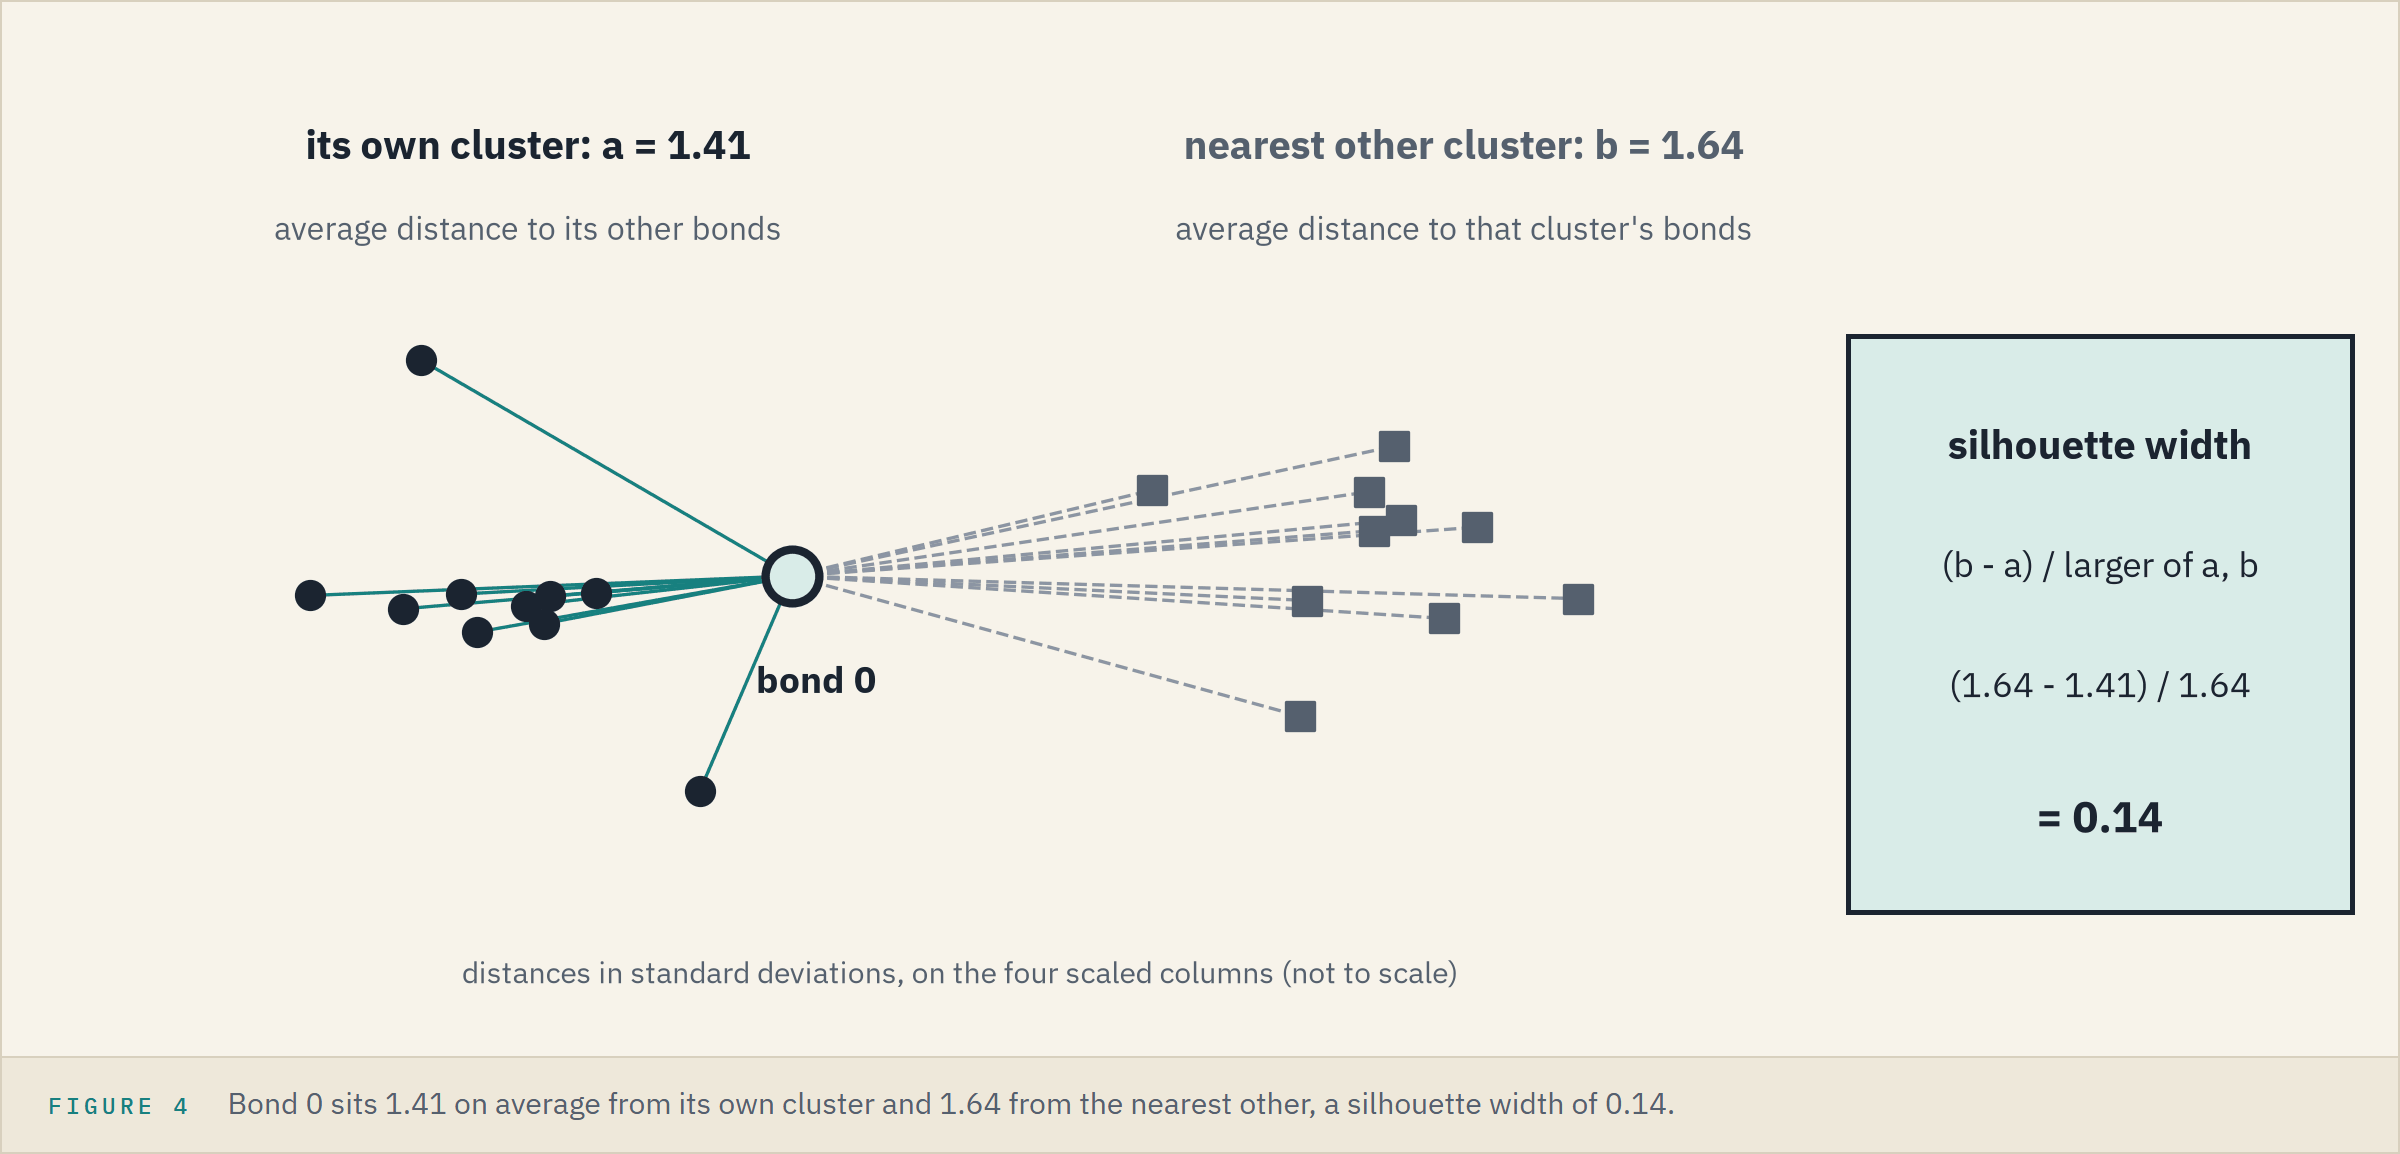

The elbow looks only inside each cluster; the **silhouette** also asks how far the next cluster is.
For one bond:

* **a**: its average distance to the other bonds of its own cluster
* **b**: its average distance to the bonds of the nearest other cluster
* **silhouette width**: (b - a) divided by the larger of a and b

A width near 1 means the bond sits deep in its cluster, near 0 on a border, and below 0 nearer another cluster than its own.
Bond 0 in today's four clusters has a of 1.41 and b of 1.64, a width of 0.14.
`silhouette_score` averages the width over every bond.

**Predict 4**

Q. We read the elbow at 4. Which k, from 2 to 10, has the highest average silhouette?

In [35]:
# the average silhouette width for k = 2 to 10 (one cluster has no other cluster to compare with)
# fit_predict fits the model and hands back its labels in one call
silhouettes = {}
for k in range(2, 11):
    labels = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X_scaled)
    silhouettes[k] = silhouette_score(X_scaled, labels)
elbow["silhouette"] = pd.Series(silhouettes)
elbow.round(3)

,inertia,fall,silhouette
k,,,
1,3284.000,NaN,NaN
2,1897.581,1386.419,0.369
3,1470.378,427.203,0.290
4,1141.828,328.550,0.293
5,987.534,154.294,0.290
6,868.093,119.441,0.283
7,763.905,104.188,0.289
8,692.330,71.575,0.291
9,633.568,58.762,0.284


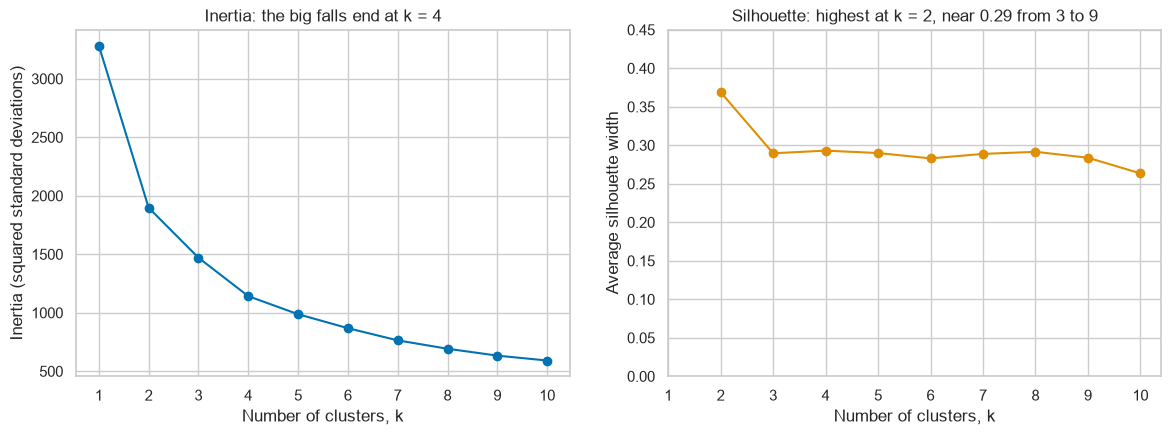

In [36]:
# the elbow beside the silhouette, the same kind of line on purpose
fig, (left, right) = plt.subplots(1, 2, figsize=(14, 4.5))
left.plot(elbow.index, elbow["inertia"], marker="o")
right.plot(elbow.index, elbow["silhouette"], marker="o", color=colours[1])
right.set_ylim(0, 0.45)
left.set_title("Inertia: the big falls end at k = 4")
right.set_title("Silhouette: highest at k = 2, near 0.29 from 3 to 9")
for ax in (left, right):
    ax.set_xticks(elbow.index)
    ax.set_xlabel("Number of clusters, k")
left.set_ylabel("Inertia (squared standard deviations)")
right.set_ylabel("Average silhouette width")
plt.show()

The silhouette is 0.369 at k = 2, then between 0.283 and 0.293 for every k from 3 to 9.
The two measures disagree.

## Silhouette Diagrams

Q. Which bonds sit badly in their cluster?
A **silhouette diagram** draws every bond's width as a thin bar, sorted within each cluster.

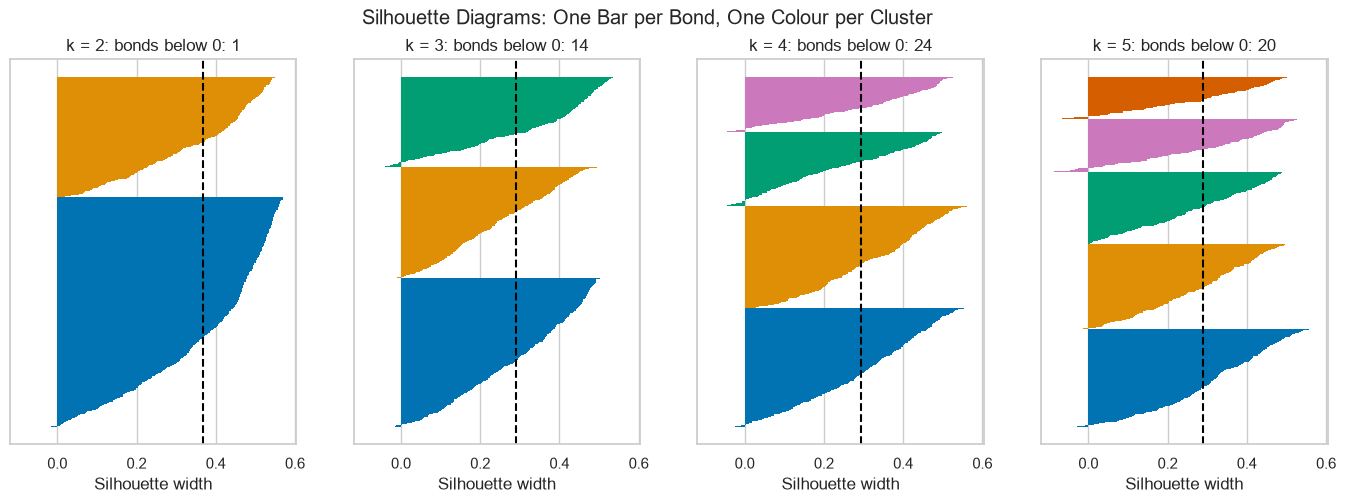

In [37]:
# every bond's silhouette width for k = 2 to 5, sorted within each cluster, the average dashed
fig, axes = plt.subplots(1, 4, figsize=(17, 5), sharex=True)
for ax, k in zip(axes, [2, 3, 4, 5]):
    labels = by_size(KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X_scaled))
    widths = pd.DataFrame({"cluster": labels, "width": silhouette_samples(X_scaled, labels)})
    widths = widths.sort_values(["cluster", "width"]).reset_index(drop=True)
    ax.barh(widths.index, widths["width"], height=1, linewidth=0, color=[colours[c] for c in widths["cluster"]])
    ax.axvline(widths["width"].mean(), color="black", linestyle="--")
    below = (widths["width"] < 0).sum()
    ax.set_title(f"k = {k}: bonds below 0: {below}")
    ax.set_xlabel("Silhouette width")
    ax.set_yticks([])
fig.suptitle("Silhouette Diagrams: One Bar per Bond, One Colour per Cluster")
plt.show()

At k = 2 two thick blades and a single bond below 0.
From k = 3 the blades thin, and 14 to 24 bonds sit nearer another cluster than their own.

## Two Clusters or Four

Q. What are the two clusters the silhouette likes best?

In [38]:
# k = 2, described with the grade column the file already has
data["k2"] = by_size(KMeans(n_clusters=2, n_init=10, random_state=SEED).fit_predict(X_scaled))
data["ig"] = data["grade"] == "Investment Grade"
data.groupby("k2").agg(bonds=("cusip", "count"), median_oas_bp=("oas", "median"), ig_share=("ig", "mean")).round(3)

,bonds,median_oas_bp,ig_share
k2,,,
0,538,92.0,0.941
1,283,256.0,0.120


With two clusters, one holds 538 bonds, 94.1 percent investment grade, median OAS 92 bp.
The other holds 283 bonds, 12.0 percent investment grade, median 256 bp.
That is close to the grade column the file already has.

**The silhouette prefers 2, which rediscovers the grade. We keep 4, which also finds a group of long bonds: a judgement, stated as one.**

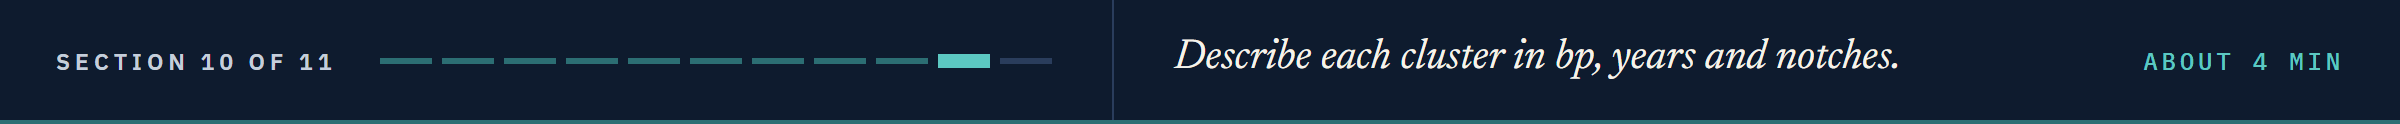

# Describing the Clusters

## The Profile in the File's Units

Q. What does each of the four clusters hold, in bp, years and notches?

In [39]:
# each cluster's size, medians in the file's own units, average score, and share of investment grade bonds
profile = data.groupby("cluster").agg(bonds=("cusip", "count"), median_oas_bp=("oas", "median"),
                                      median_duration=("duration", "median"), median_coupon=("coupon", "median"),
                                      mean_score=("score", "mean"), ig_share=("ig", "mean"))
profile.round(3)

,bonds,median_oas_bp,median_duration,median_coupon,mean_score,ig_share
cluster,,,,,,
0,278,71.0,4.615,4.625,6.158,1.000
1,239,174.0,4.710,5.875,10.736,0.456
2,175,115.0,9.898,5.750,8.137,0.869
3,129,385.0,5.725,8.250,14.659,0.008


Cluster 0: 278 bonds, median OAS 71 bp, average score 6.2, every one investment grade.
Cluster 1: 239 bonds, median 174 bp, average score 10.7, 45.6 percent investment grade, the middle of the scale.
Cluster 2: 175 bonds, median 115 bp and a median duration of 9.9 years, the long bonds.
Cluster 3: 129 bonds, median 385 bp, average score 14.7, one bond in investment grade.

## Each Cluster's Fingerprint

Q. How does each cluster's centre sit against the average bond, column by column?

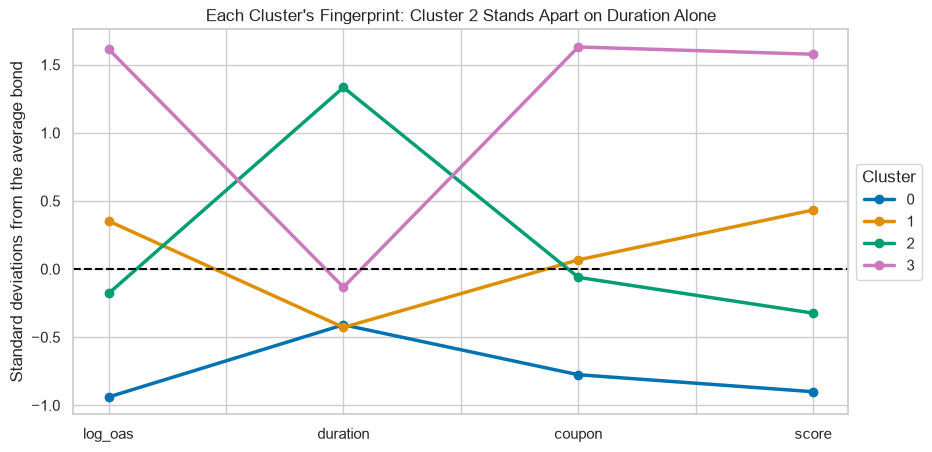

In [40]:
# each cluster's average on the four scaled columns: 0 is the average bond
fingerprint = X_scaled.groupby(data["cluster"]).mean()
fingerprint.T.plot(marker="o", linewidth=2.5, color=colours[:4])
plt.axhline(0, color="black", linestyle="--")
plt.ylabel("Standard deviations from the average bond")
plt.legend(title="Cluster", loc="center left", bbox_to_anchor=(1, 0.5))
plt.title("Each Cluster's Fingerprint: Cluster 2 Stands Apart on Duration Alone")
plt.show()

Clusters 0 and 3 mirror each other: cluster 0 sits below the average bond on log OAS, coupon and score, cluster 3 well above it.
Cluster 2 sits near the average on everything but duration.
Cluster 1 is a little above the average on spread and score, and below it on duration.

## The Spread Inside Each Cluster

Q. Does a cluster have hard edges?

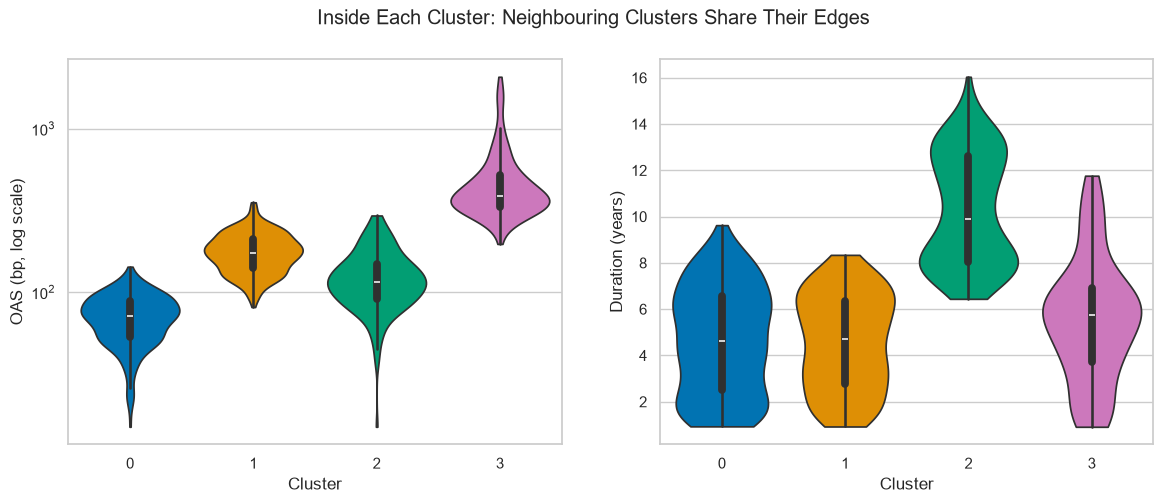

In [41]:
# OAS and duration inside each cluster: a violin shows the whole shape
# log_scale=True draws OAS on a log axis; saturation=1 keeps the cluster colours of the other charts
fig, (left, right) = plt.subplots(1, 2, figsize=(14, 5))
sns.violinplot(data=data, x="cluster", y="oas", hue="cluster", palette=colours[:4], legend=False, log_scale=True,
               cut=0, saturation=1, ax=left)
sns.violinplot(data=data, x="cluster", y="duration", hue="cluster", palette=colours[:4], legend=False,
               cut=0, saturation=1, ax=right)
left.set_ylabel("OAS (bp, log scale)")
right.set_ylabel("Duration (years)")
left.set_xlabel("Cluster")
right.set_xlabel("Cluster")
fig.suptitle("Inside Each Cluster: Neighbouring Clusters Share Their Edges")
plt.show()

The clusters overlap at their edges: some bonds in cluster 1 are wider than some in cluster 3.
A cluster is a region where similar bonds crowd, not a box with walls.

## The Clusters in Three Dimensions

Q. Seen in three columns at once, do the clusters look separate?

In [42]:
# rest the pointer on a dot to see the bond; drag to turn the cube
fig = px.scatter_3d(data, x="log_oas", y="duration", z="score", color=data["cluster"].astype(str),
                    hover_name="issuer", hover_data=["rating", "oas"], color_discrete_sequence=colours,
                    category_orders={"color": ["0", "1", "2", "3"]},
                    labels={"log_oas": "Log OAS", "duration": "Duration (years)", "score": "Rating score", "color": "Cluster"},
                    title="Clusters 0, 1 and 3 Stack Up the Rating Score; Cluster 2 Holds the Long Bonds")
fig.update_traces(marker_size=3)
fig.show()

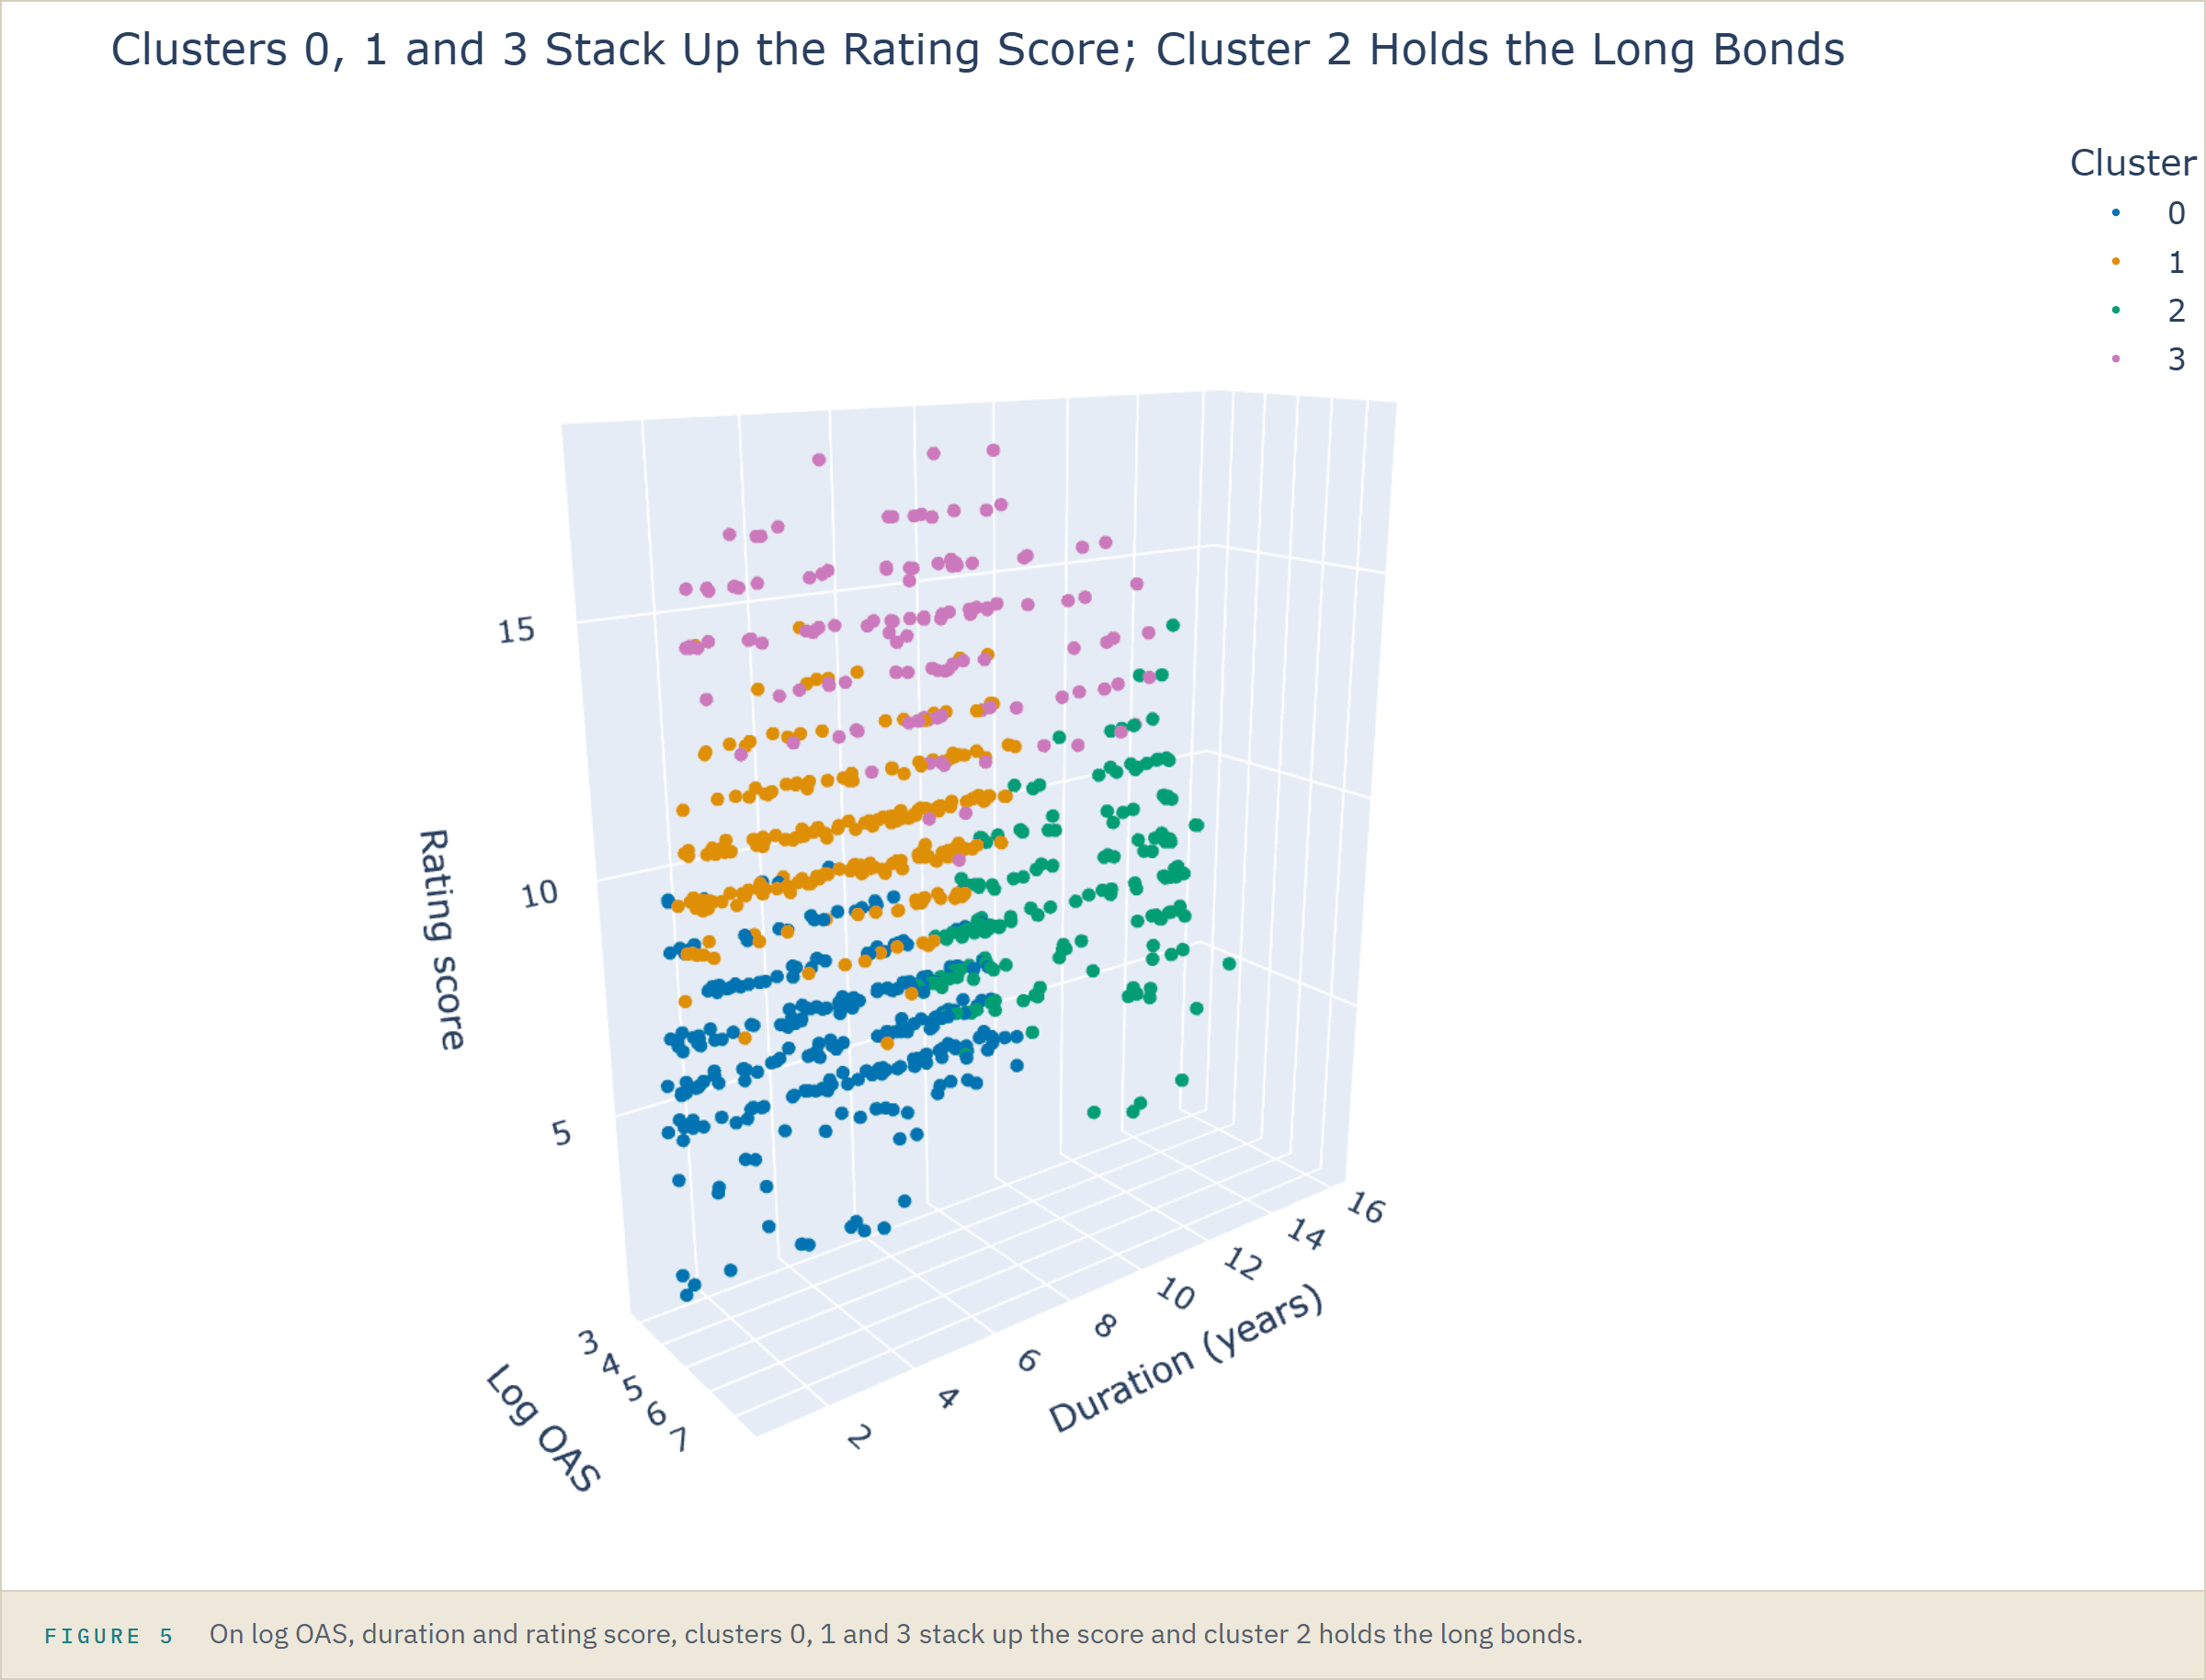

Turned this way, clusters 0, 1 and 3 stack up the rating score, and cluster 2 holds the long bonds, across most of the scale.

**A cluster is a group of similar rows in this file: it describes the bonds, and it ranks nothing.**

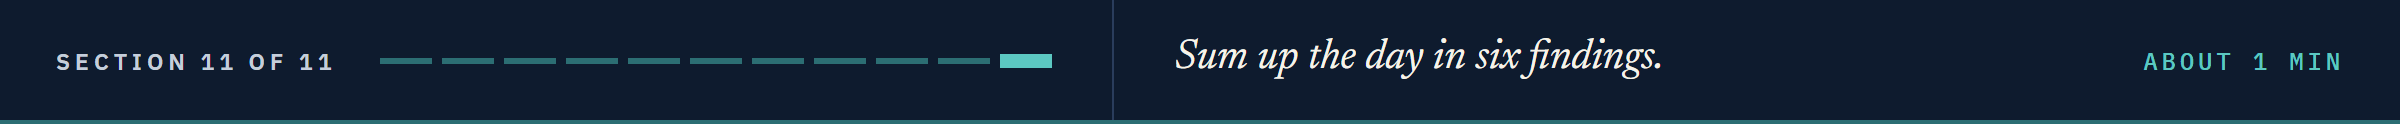

# Insights and Conclusion

A distance hears the loudest unit: in bp, OAS's median share of a pair's squared distance is 99.6 percent.
Unscaled, K-means cut OAS into four slices; with OAS in percent it cut on duration and the rating score instead.
Scaled, every column has a say, and changing the units moves no bond.
The loop is assign and update, repeated; a single start can settle badly, so `n_init=10`.
We read the elbow at 4 and the silhouette prefers 2: k is a judgement, and we stated ours.
The four clusters are described in bp, years and notches: groups of similar bonds, not a ranking.

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Measure the distance between two bonds and see which column makes it up.
* Scale columns with `StandardScaler` before any method built on distance.
* Fit K-means with `n_init` written out, number the clusters by size, and follow its loop round by round.
* Choose k with the elbow and the silhouette, and say it is a judgement.
* Describe clusters in the file's own units without ranking them.

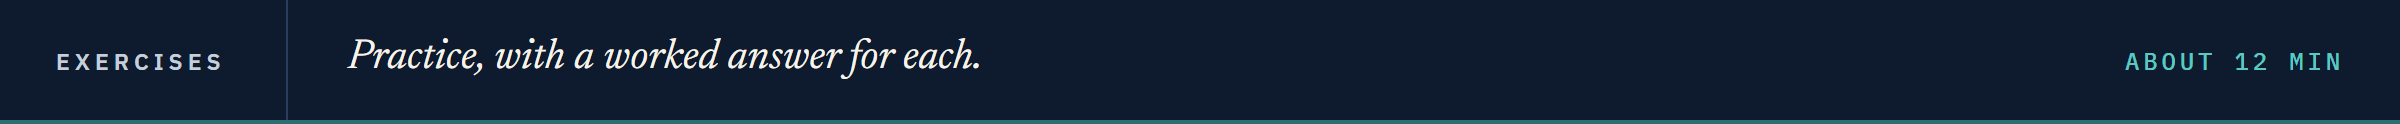

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [43]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**A Fifth Column**

Q. Add `amount_outstanding` to the four features, scale the five columns, and fit four clusters as above. Store the average silhouette in `ex1_silhouette` and the cluster sizes, largest first, as a list in `ex1_sizes`.

In [44]:
# your code here
ex1_silhouette = ...
ex1_sizes = ...

In [45]:
check("Exercise 1 the silhouette", ex1_silhouette, 0.21992362045331745)
check("Exercise 1 the sizes", ex1_sizes, [283, 231, 180, 127])

Exercise 1 the silhouette: not attempted yet
Exercise 1 the sizes: not attempted yet


### Exercise 2

**Investment Grade Only**

Q. Keep only the investment grade bonds, scale their four columns on them, and find the k from 2 to 8 with the highest average silhouette. Store it in `ex2_best_k` and the silhouette at k = 4 in `ex2_silhouette_4`.

In [46]:
# your code here
ex2_best_k = ...
ex2_silhouette_4 = ...

In [47]:
check("Exercise 2 the best k", ex2_best_k, 2)
check("Exercise 2 the silhouette at k = 4", ex2_silhouette_4, 0.23440881348670242)

Exercise 2 the best k: not attempted yet
Exercise 2 the silhouette at k = 4: not attempted yet


### Exercise 3

**Counting the Clusters**

Q. Write `cluster_sizes(labels)`, which returns a Series of how many rows carry each cluster number, indexed by the number in order. Store its result on `[2, 0, 1, 1, 2, 2]` as a dictionary in `ex3_small`, and on `data["cluster"]` as a dictionary in `ex3_today`.

In [48]:
# your code here
ex3_small = ...
ex3_today = ...

In [49]:
check("Exercise 3 the small list", ex3_small, {0: 1, 1: 2, 2: 3})
check("Exercise 3 today's clusters", ex3_today, {0: 278, 1: 239, 2: 175, 3: 129})

Exercise 3 the small list: not attempted yet
Exercise 3 today's clusters: not attempted yet


### Exercise 4: AI check

**The Duration Groups**

You asked an AI assistant for four duration groups from the bonds' OAS and duration.
This came back.
It runs, and the groups have sensible sizes.
Test it against what you already know, then find the one bug.

In [50]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def duration_groups(bonds):
    # cluster the bonds on spread and duration into four duration groups, largest first
    columns = bonds[["oas", "duration"]]
    labels = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit_predict(columns)
    return by_size(labels).value_counts().tolist()

# the check against what we know: the sizes, and the columns K-means was given
print(duration_groups(data))
print(data[["oas", "duration"]].std().round(2).tolist())

[558, 212, 45, 6]
[185.52, 3.25]


Q. The sizes match the unscaled clusters, which were slices of OAS, and the two columns' standard deviations are far from 1. Fix the one wrong line so K-means gets scaled columns, and store the fixed function's sizes in `ex4_sizes`.

In [51]:
# your code here
ex4_sizes = ...

In [52]:
check("Exercise 4 the fixed function's sizes", ex4_sizes, [368, 340, 104, 9])

Exercise 4 the fixed function's sizes: not attempted yet


## Congratulations!

You found groups in 821 bonds with no target to guide you, which is a different kind of machine learning from everything before it.
You measured a distance by hand, caught OAS drowning out every other column, and fixed it with one scaler.
You stepped through the K-means loop round by round and watched a poor start settle.
You weighed the elbow against the silhouette, chose four clusters, and said why.
In Day 13 you build clusters from the bottom up, read them off a tree, and profile them in full.

[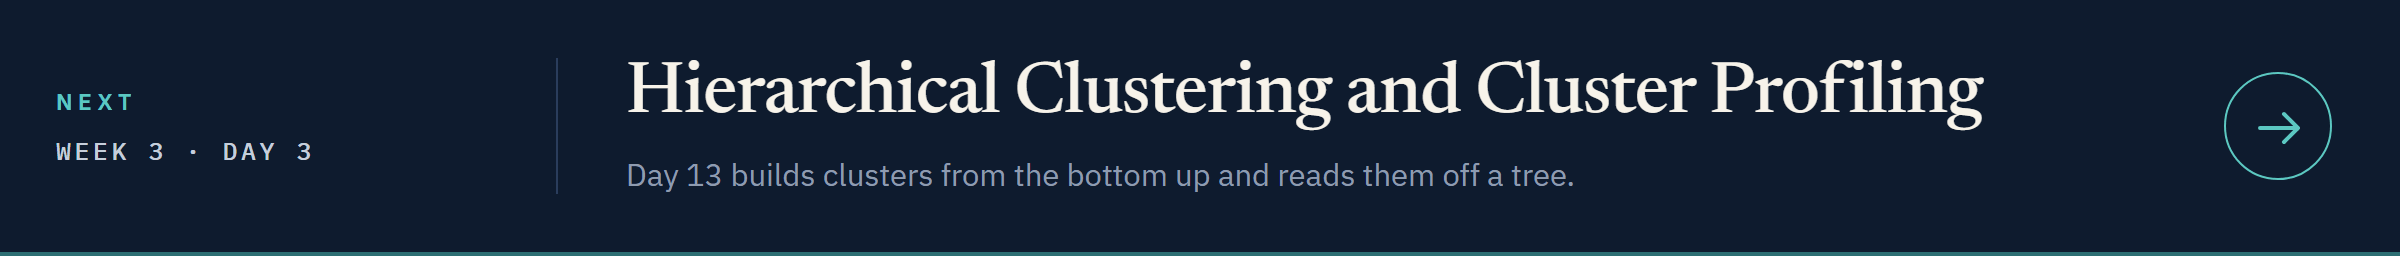](../day3/13_hierarchical_clustering_and_cluster_profiling.ipynb)

[Open Day 3 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course04_machine_learning/week3/day3/13_hierarchical_clustering_and_cluster_profiling.ipynb)